Precomputing base directional features at 2-second resolution...
Computing for window 2.....
Computing for window 4.....
Computing for window 8.....
Computing for window 16.....
Computing for window 32.....
Computing for window 64.....
Computing for window 128.....
Computing for window 256.....
Computing for window 512.....
Computing for window 768.....
Computing for window 1024.....
Computing for window 1280.....
Computing for window 1536.....
Computing for window 1792.....
Computing for window 2048.....
Computing for window 2304.....
Computing for window 2560.....
Computing for window 2816.....
Computing for window 3072.....
Computing for window 3328.....
Computing for window 3584.....
Computing for window 3840.....
Computing for window 4096.....
Computing for window 4352.....
Computing for window 4608.....
Computing for window 4864.....
Computing for window 5120.....
Computing for window 5376.....
Computing for window 5632.....
Computing for window 5888.....
Computing for window 614

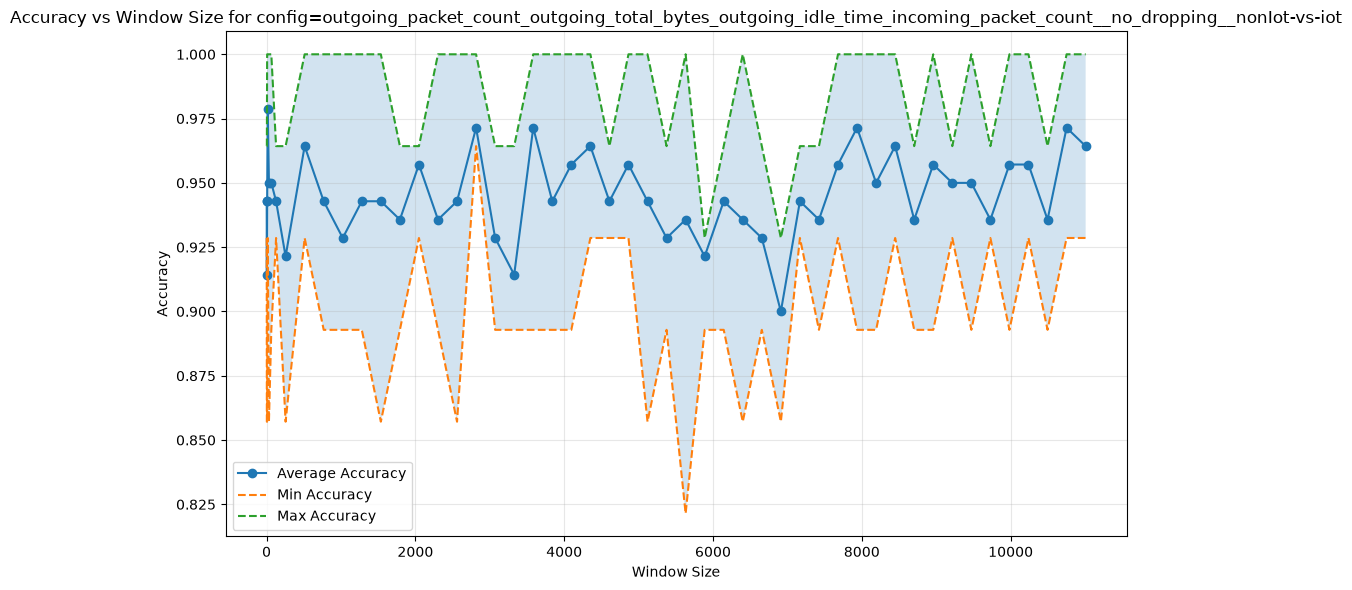

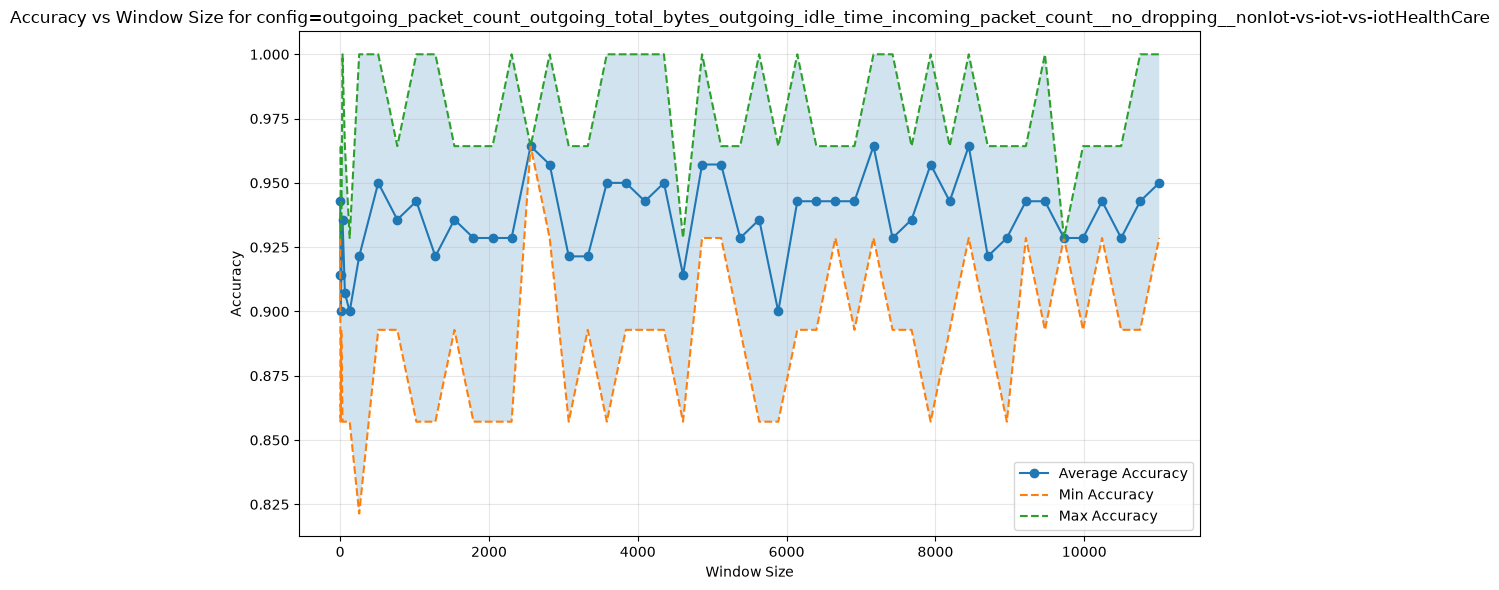

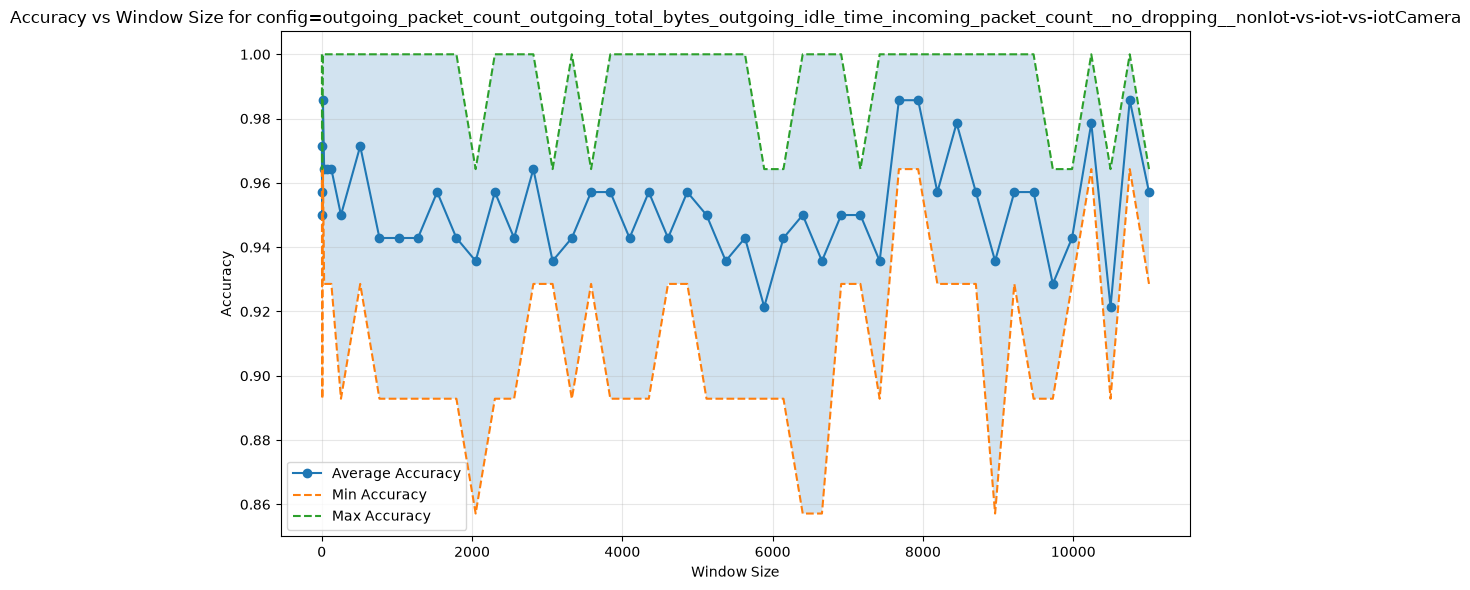

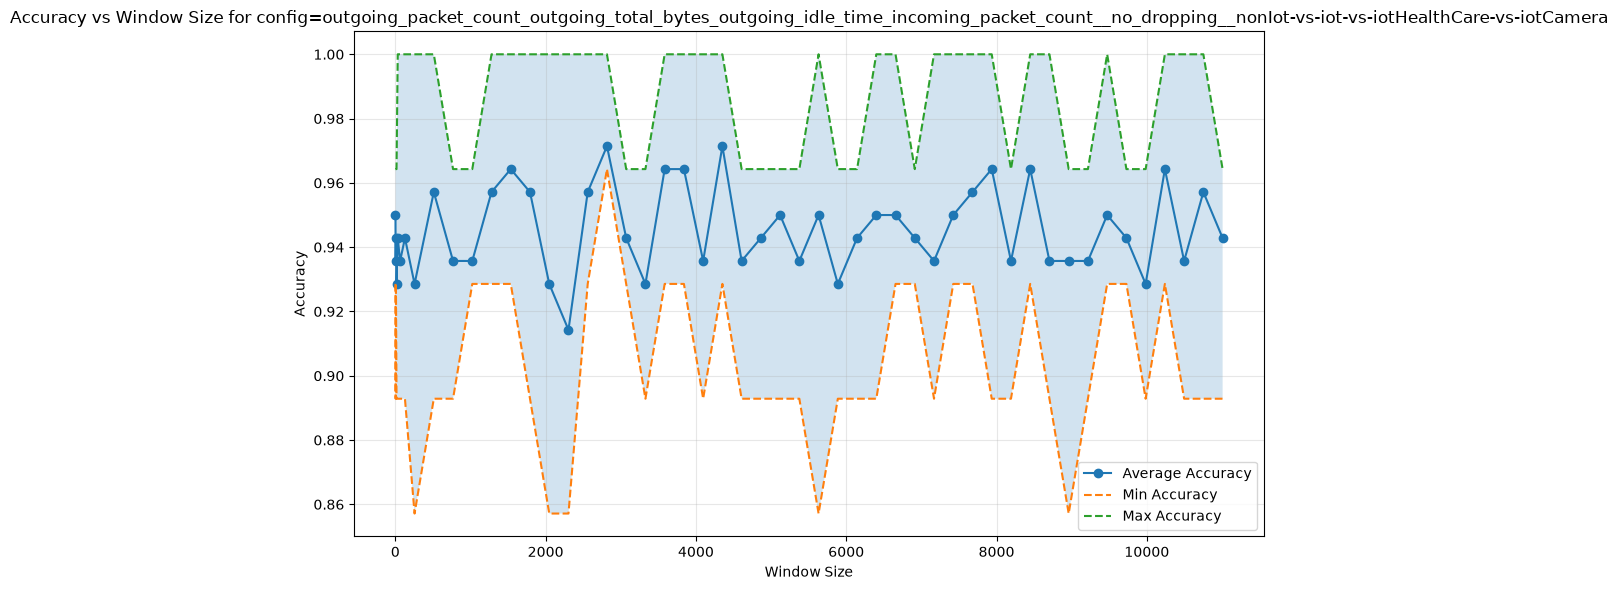

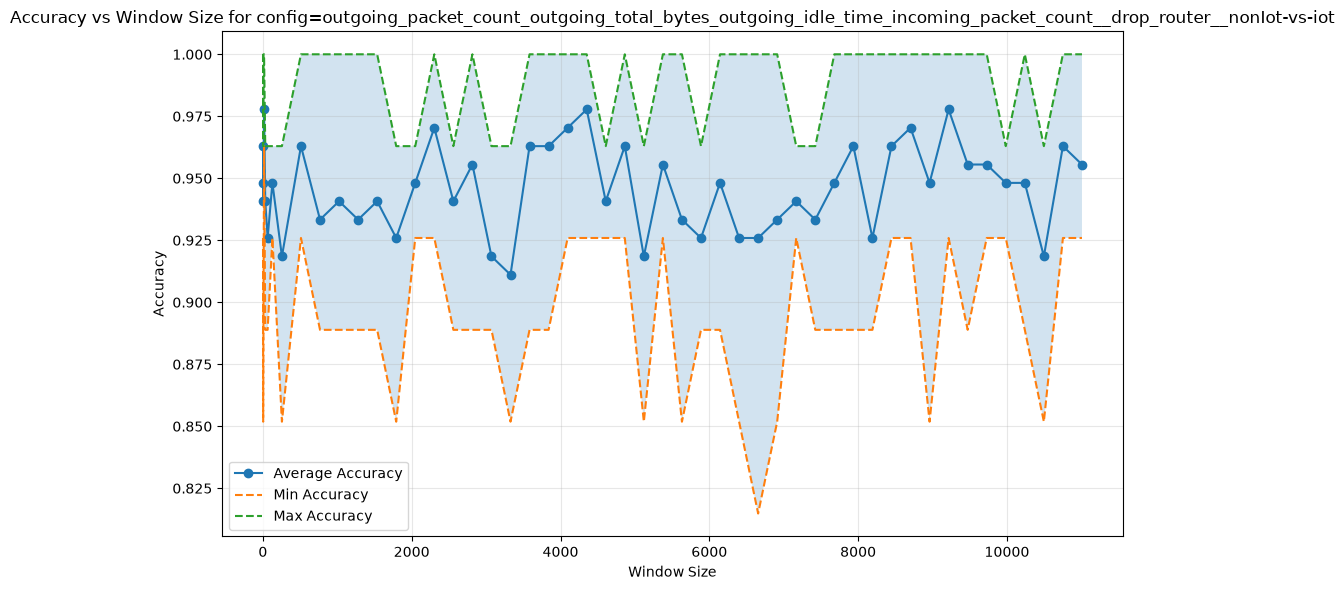

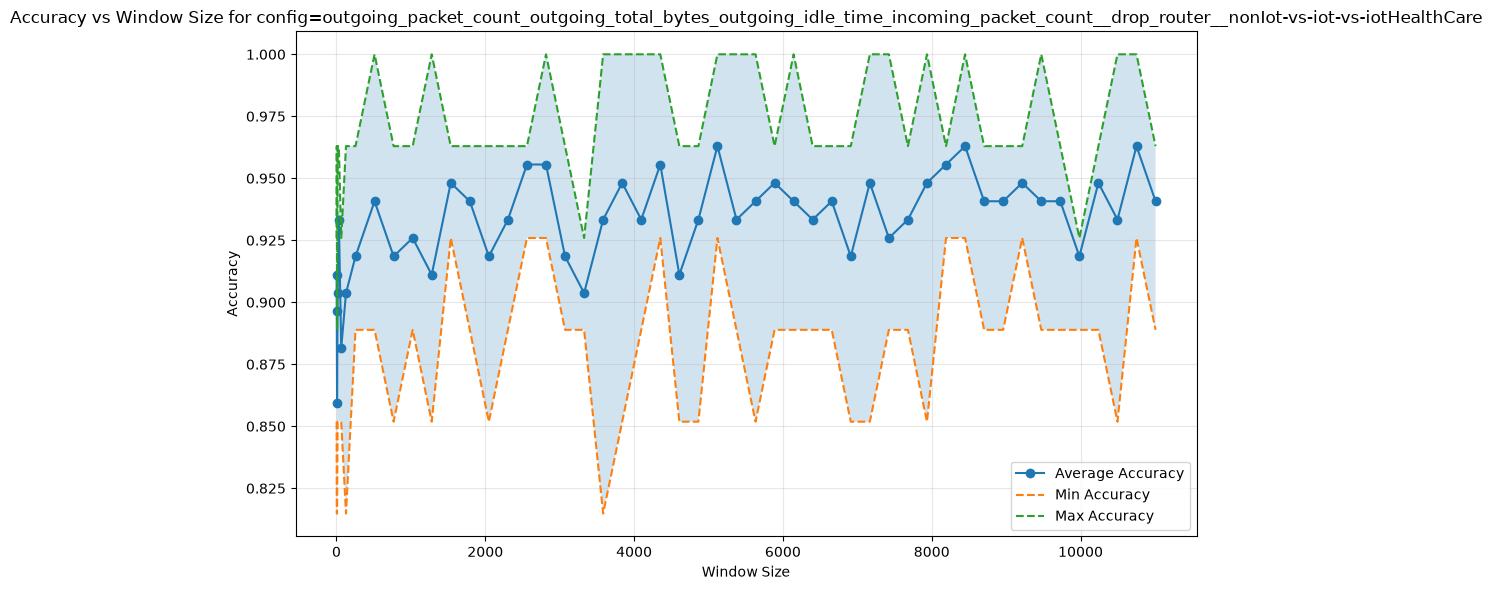

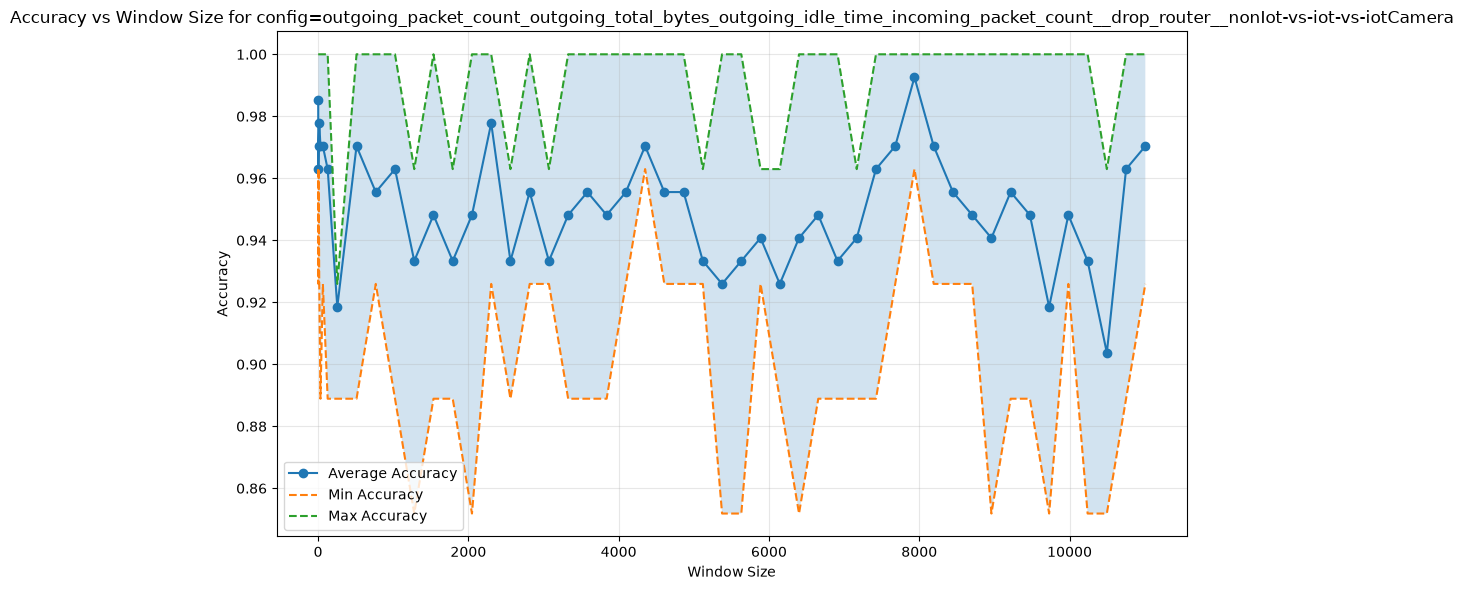

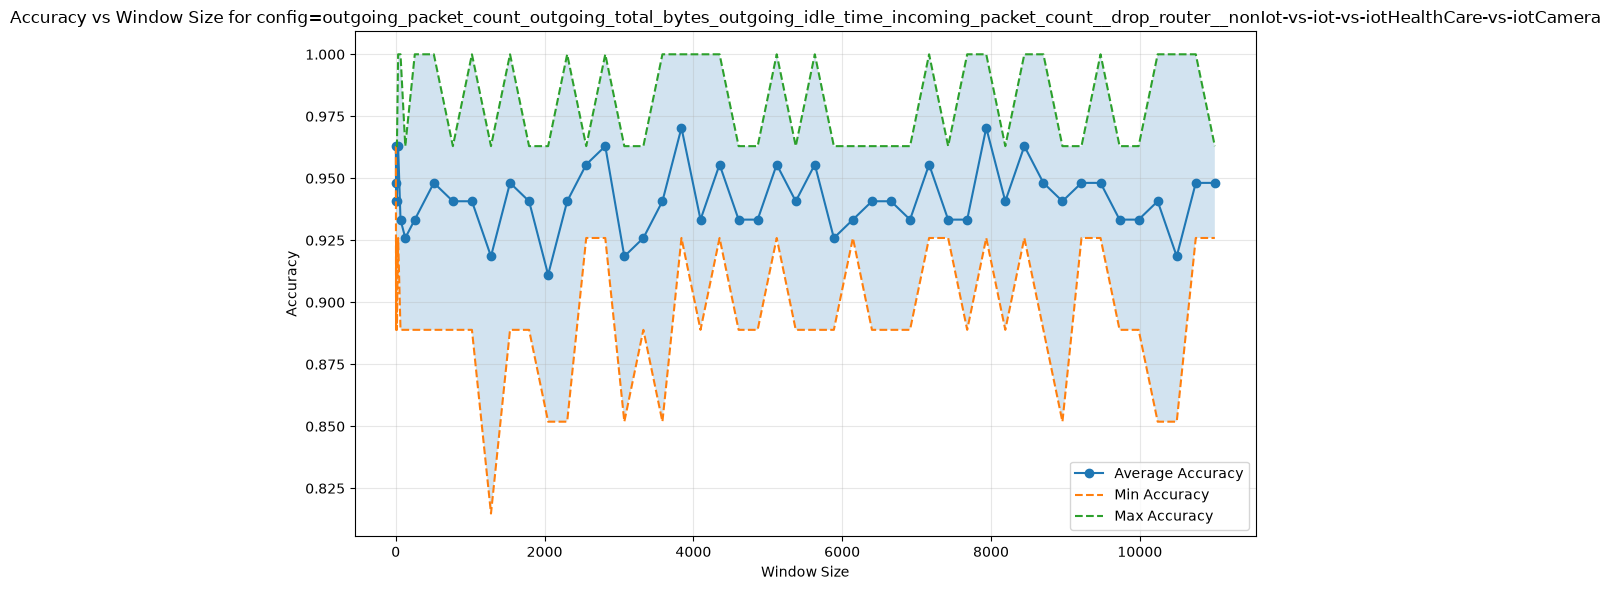

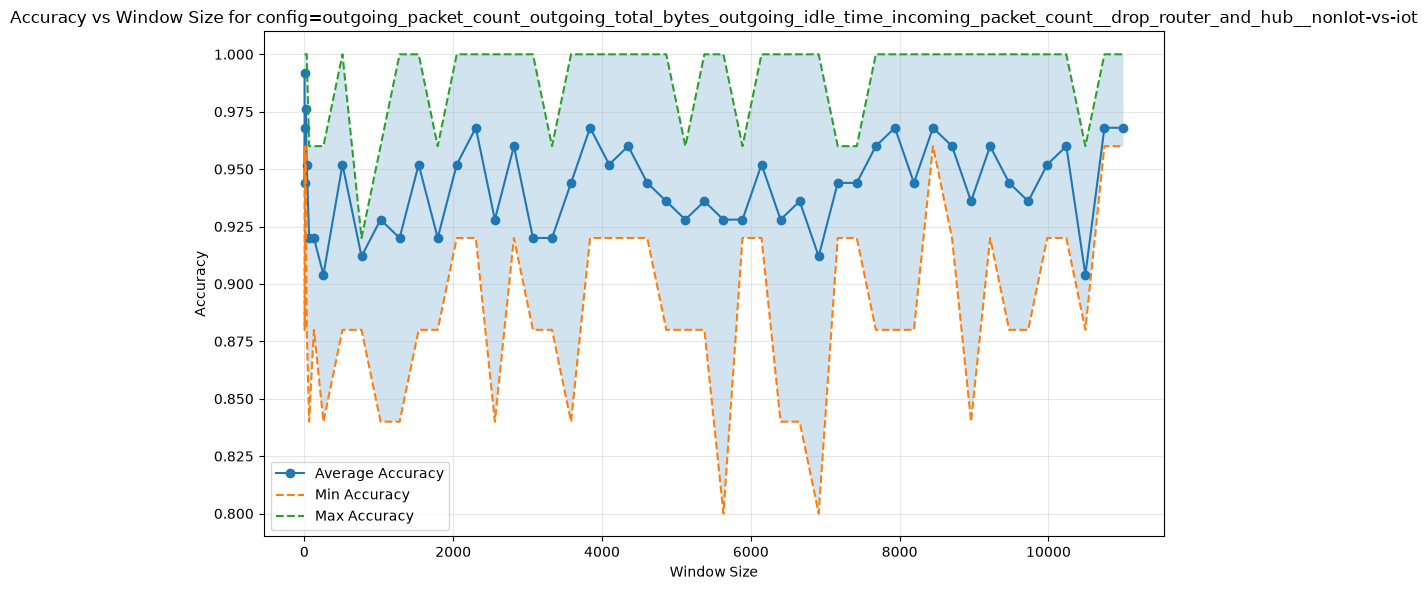

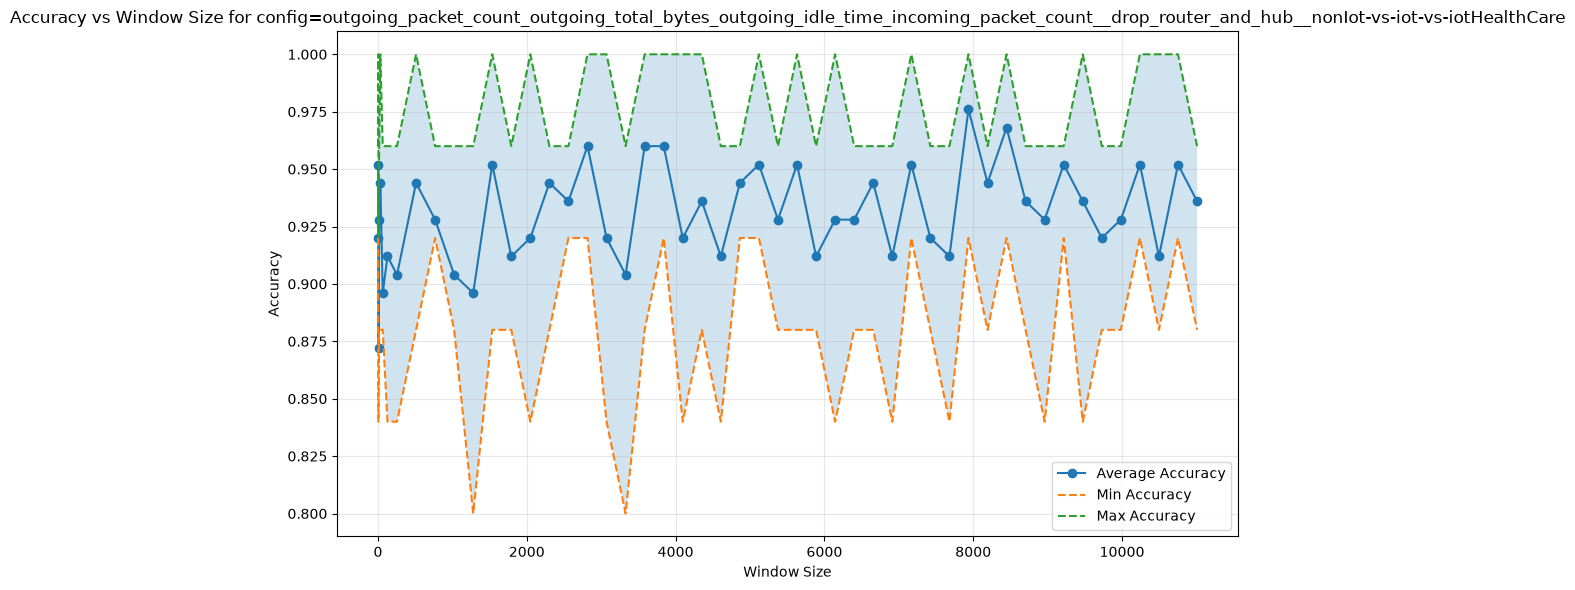

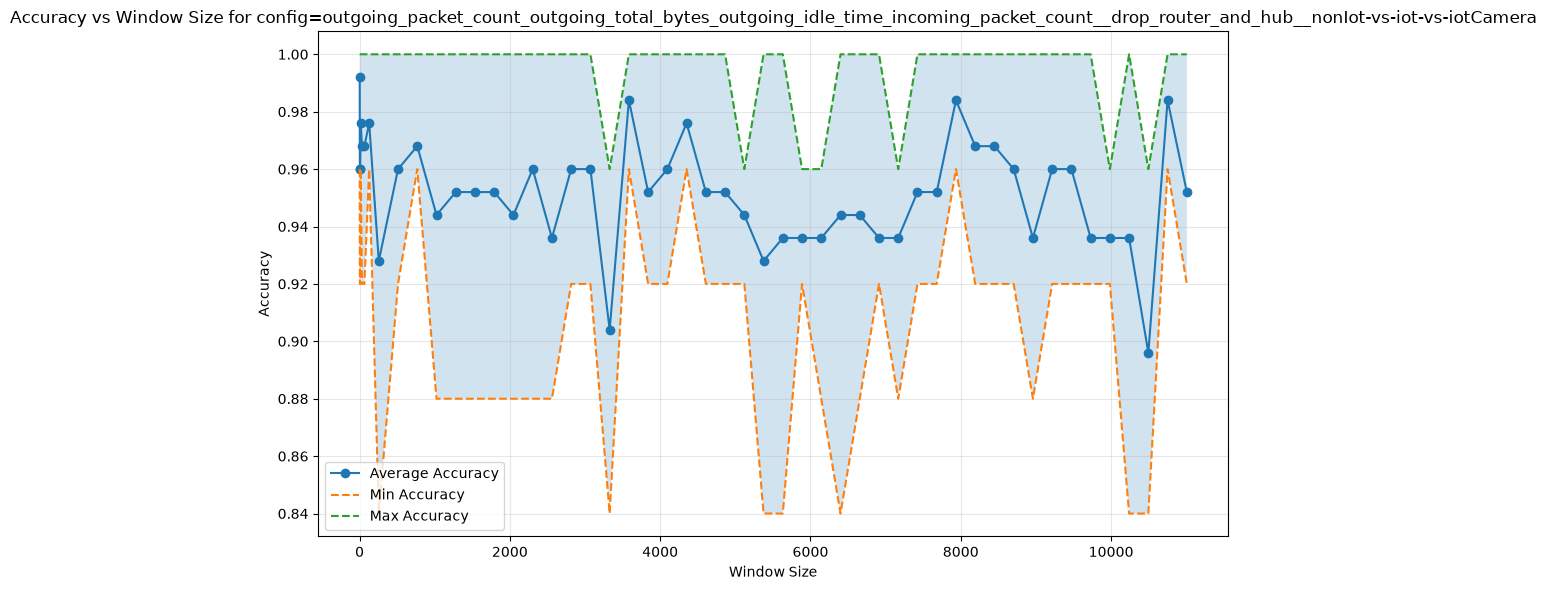

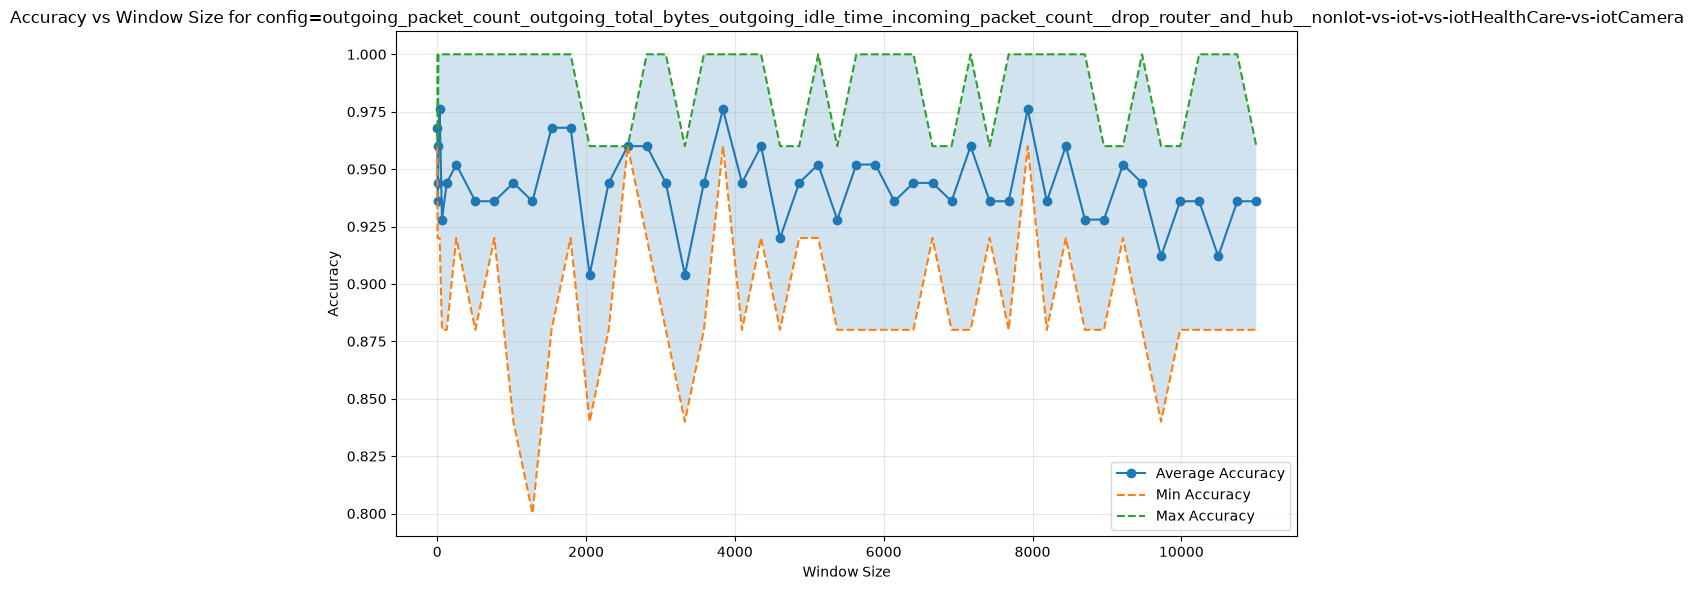

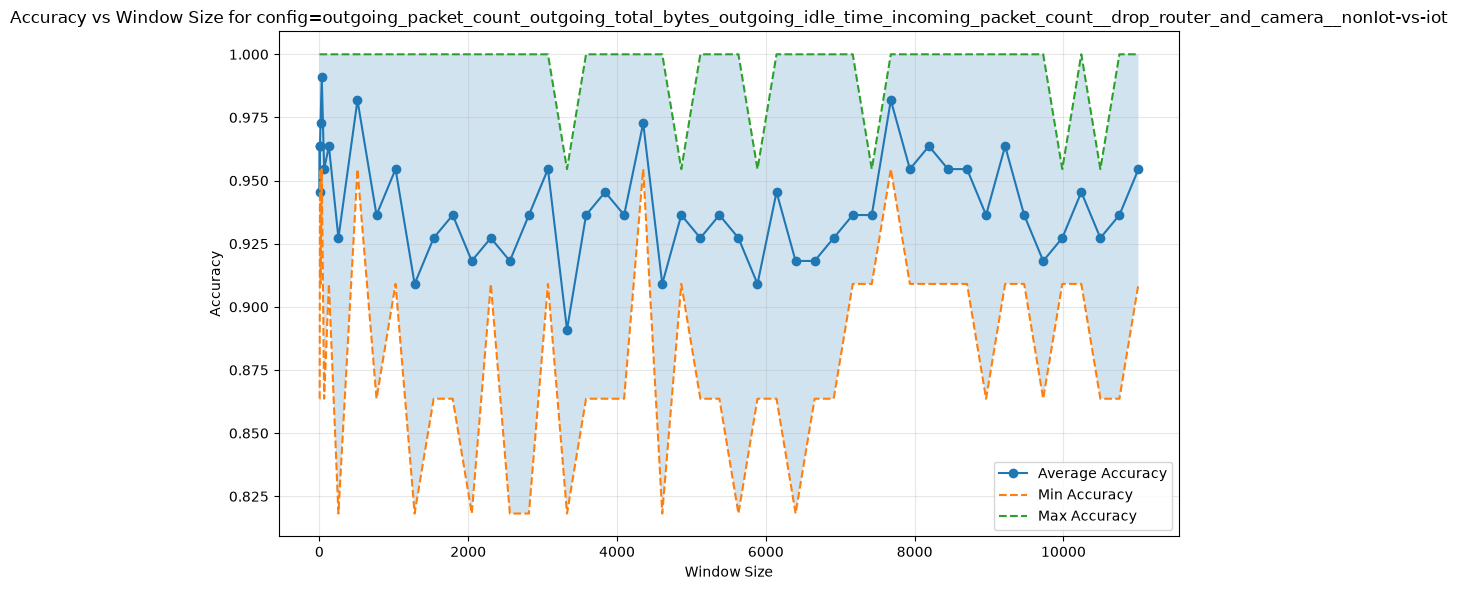

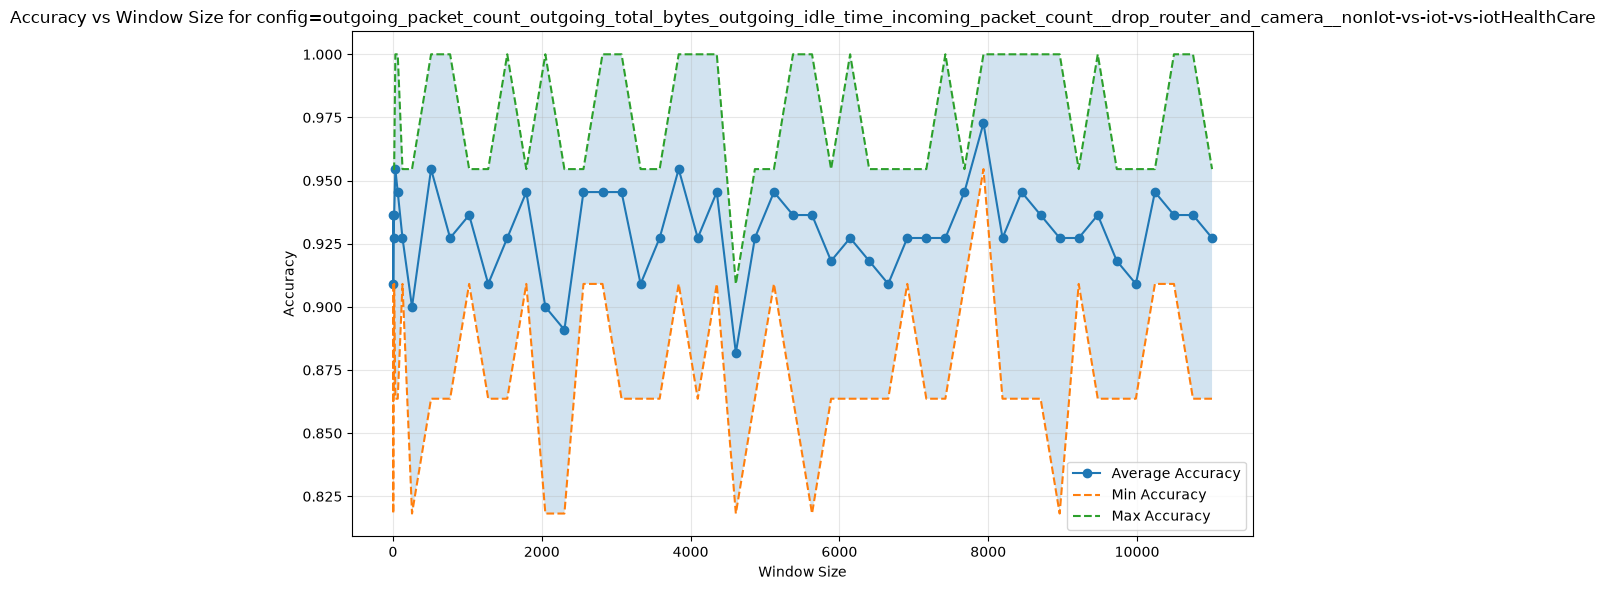

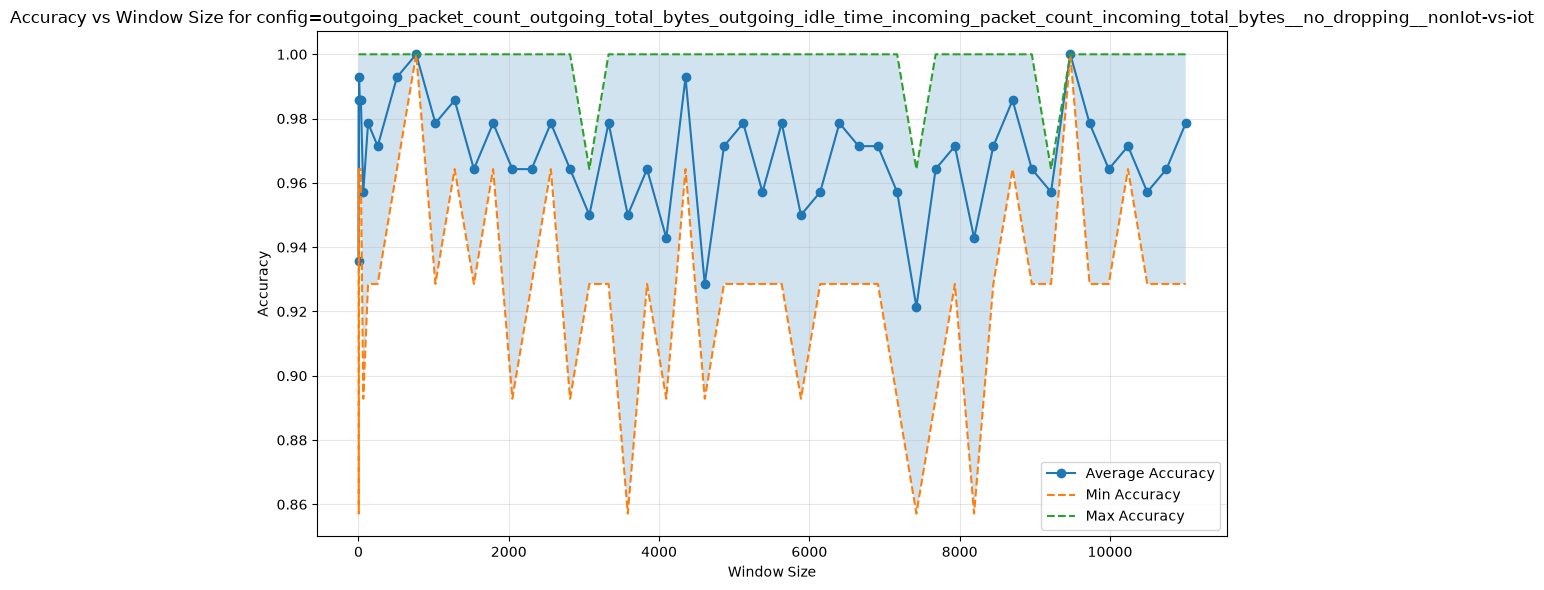

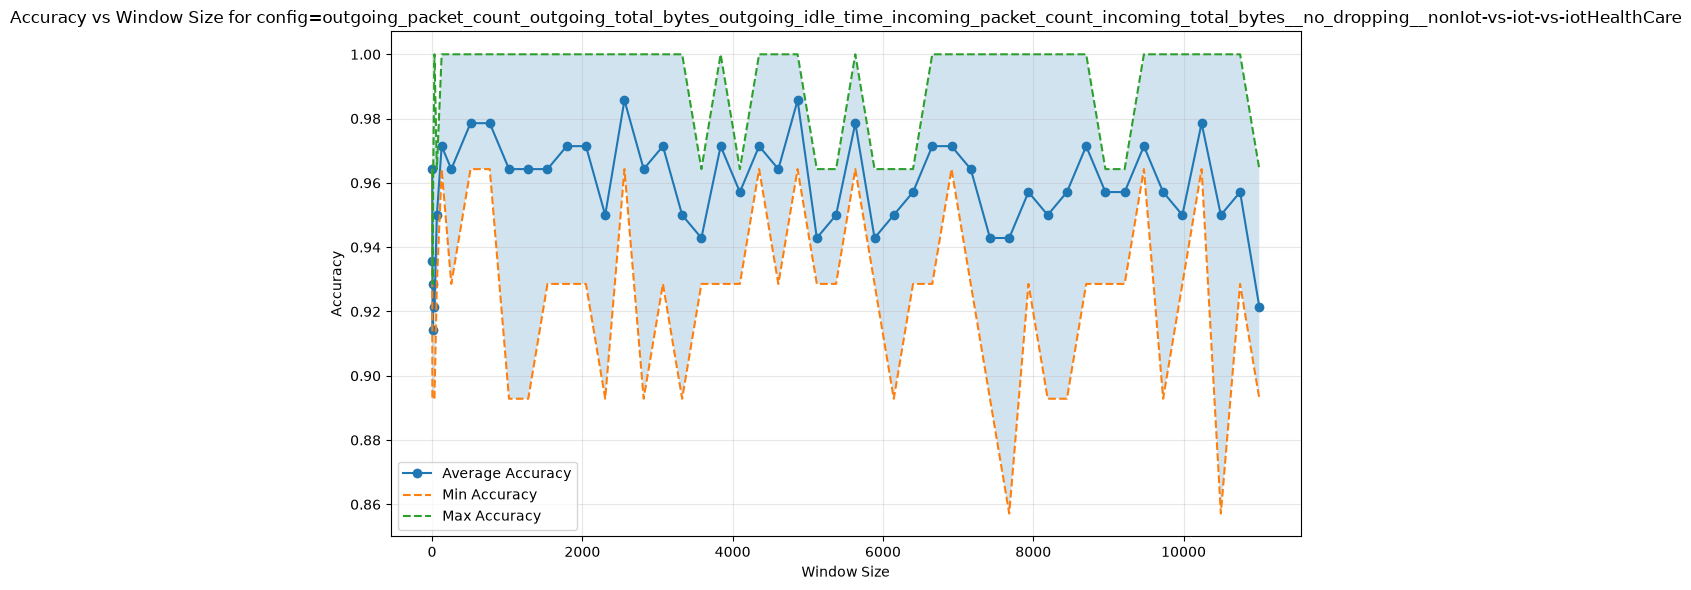

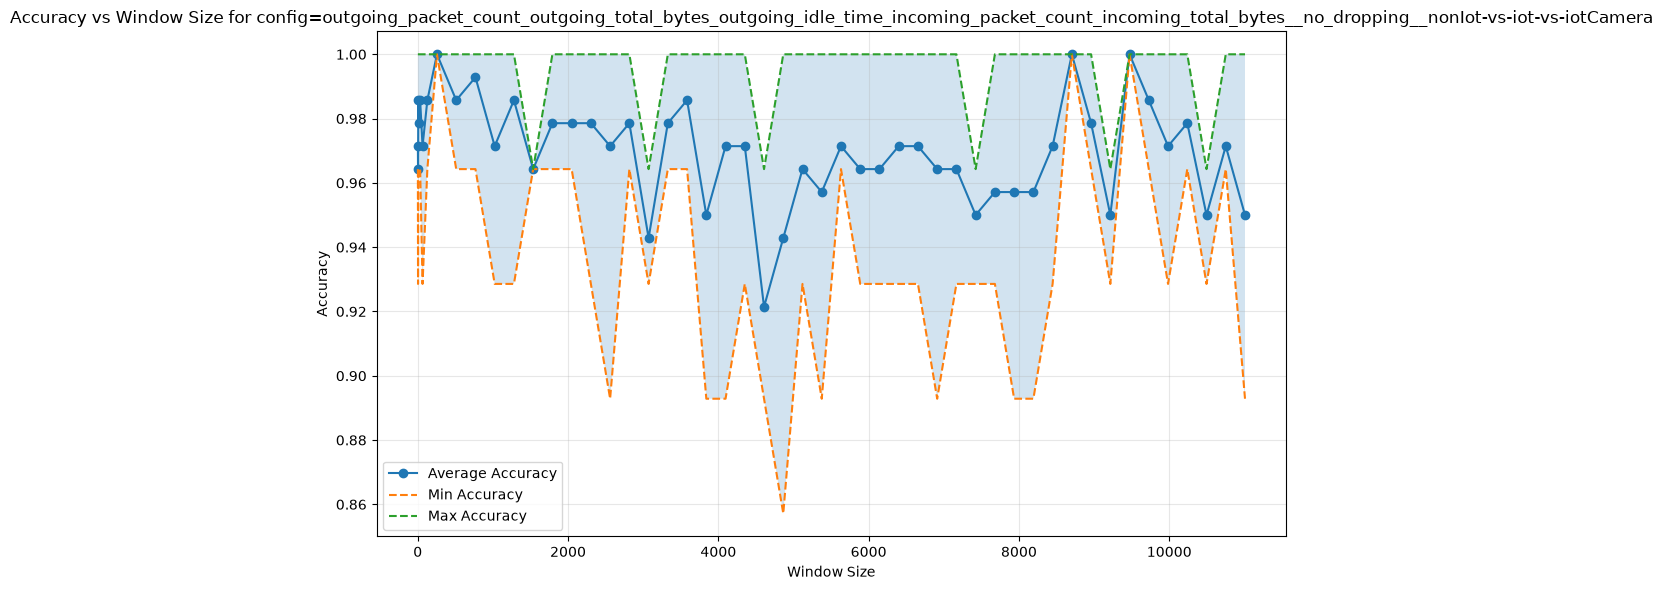

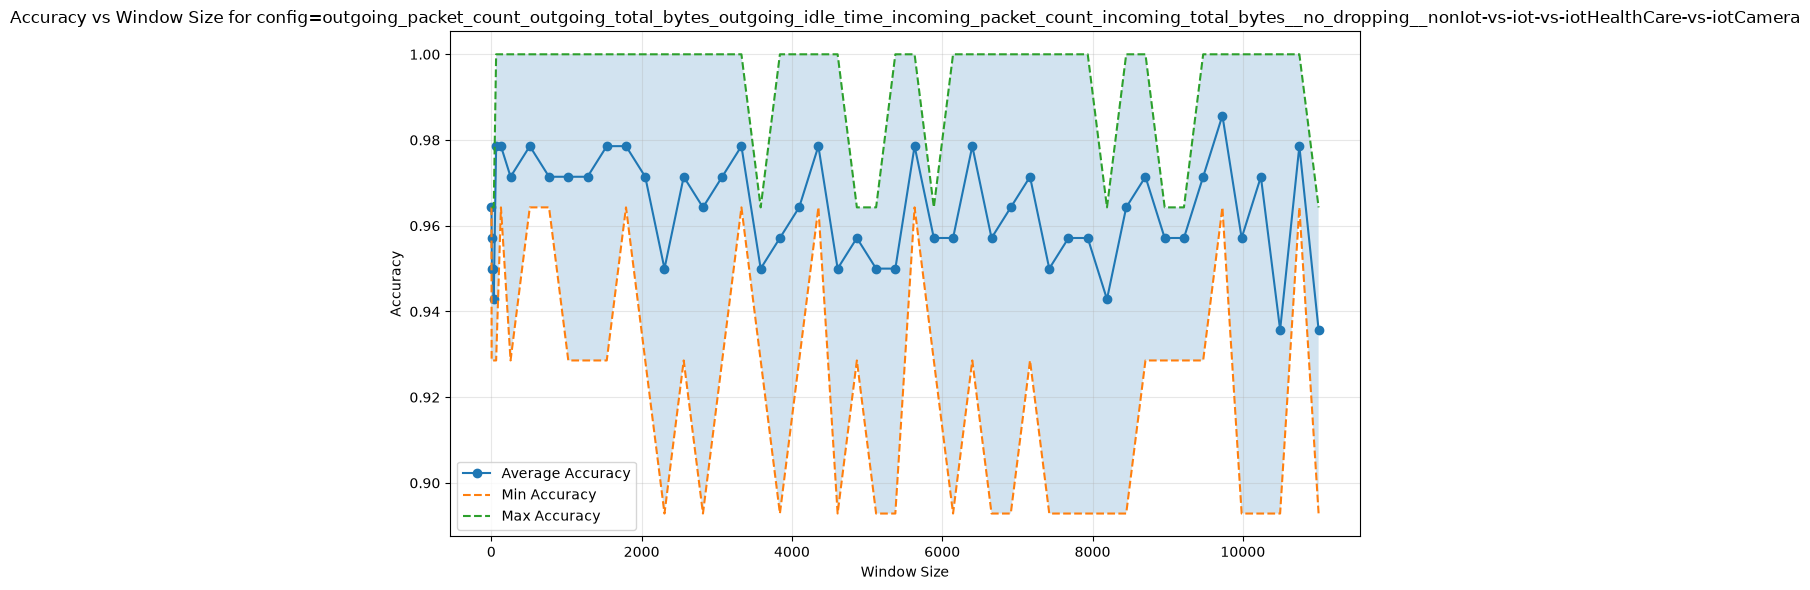

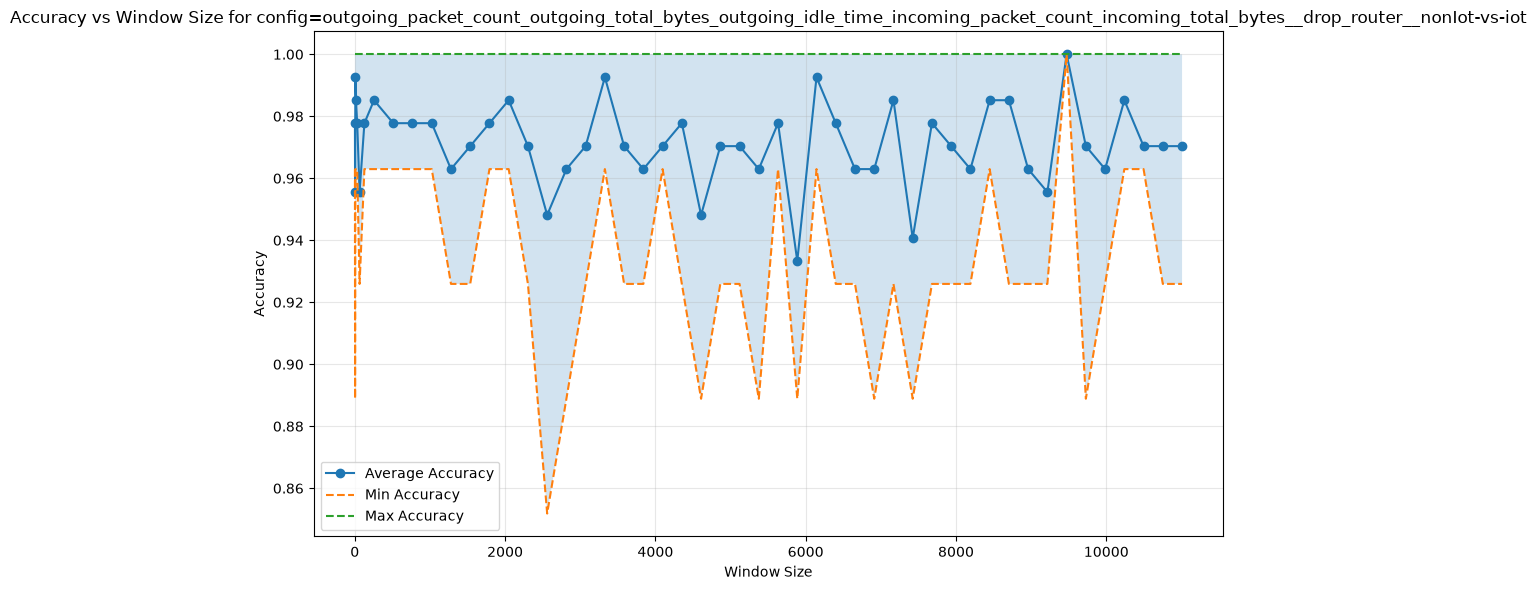

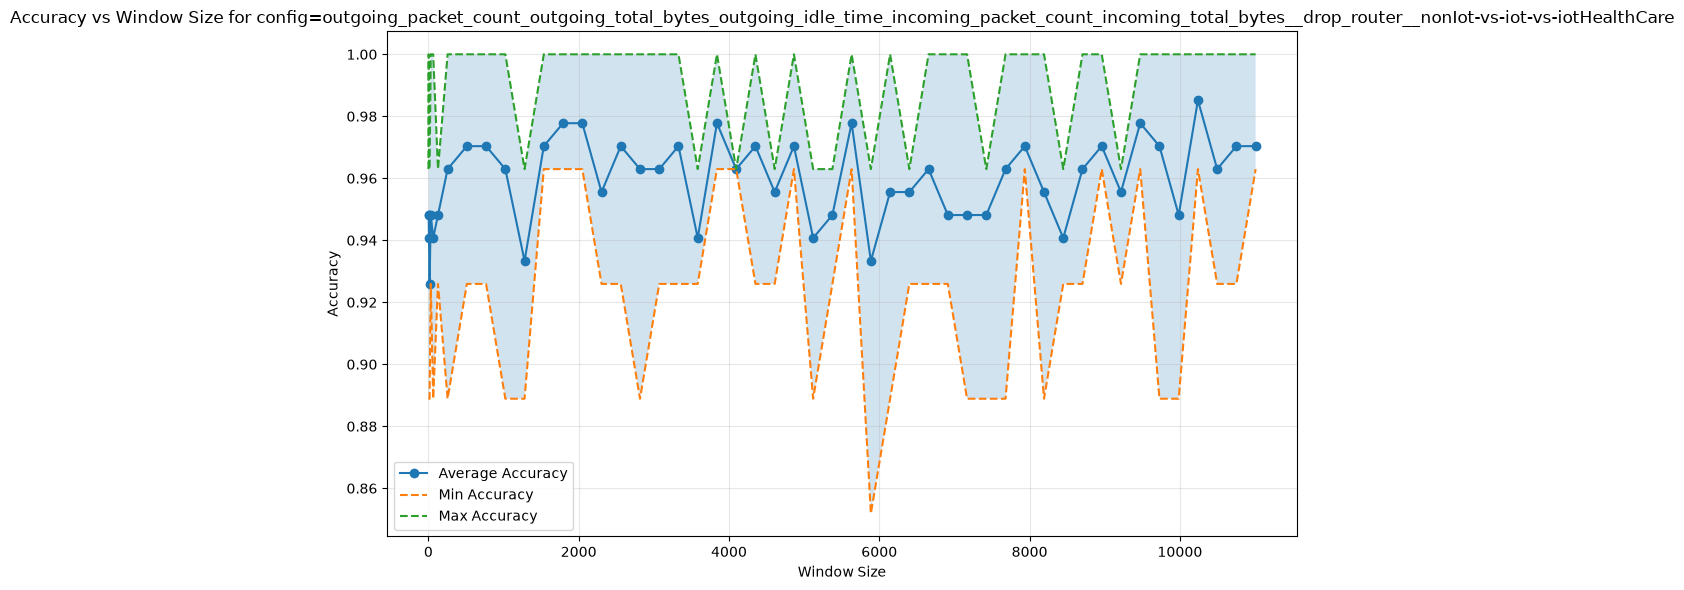

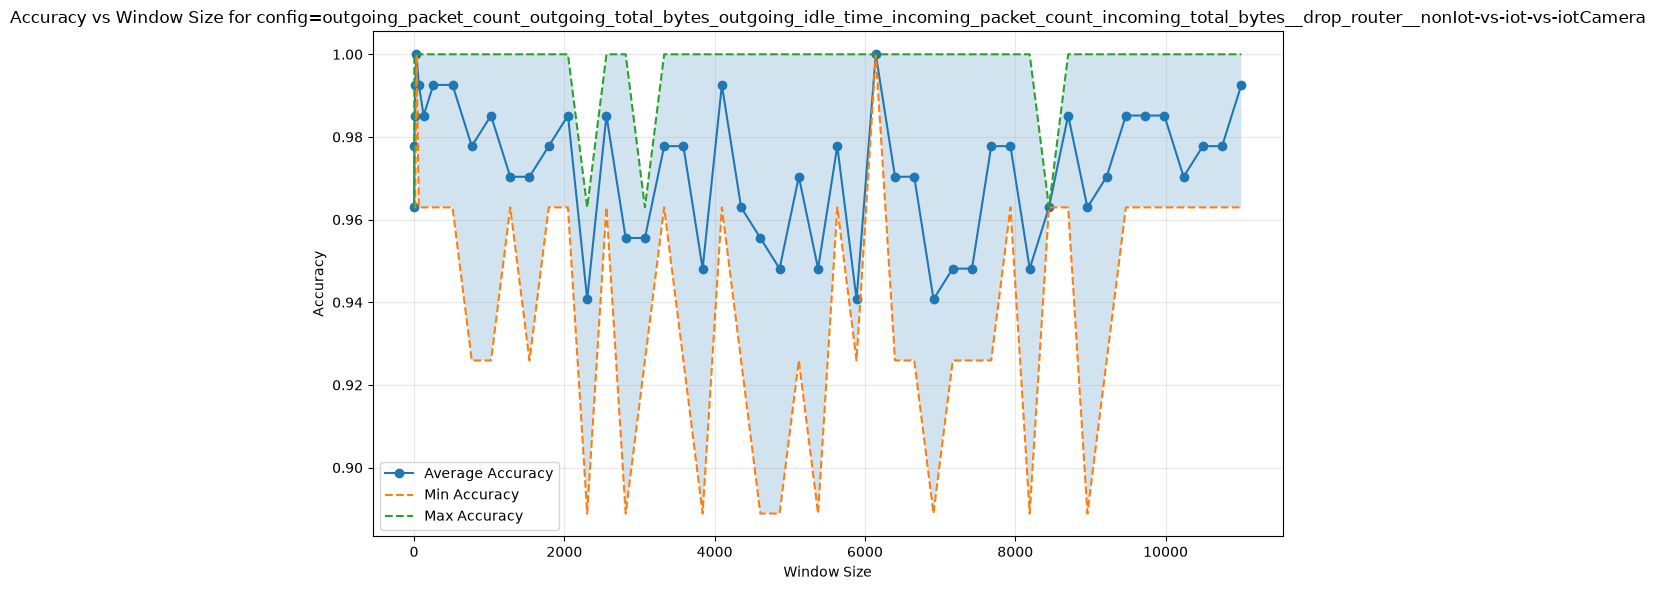

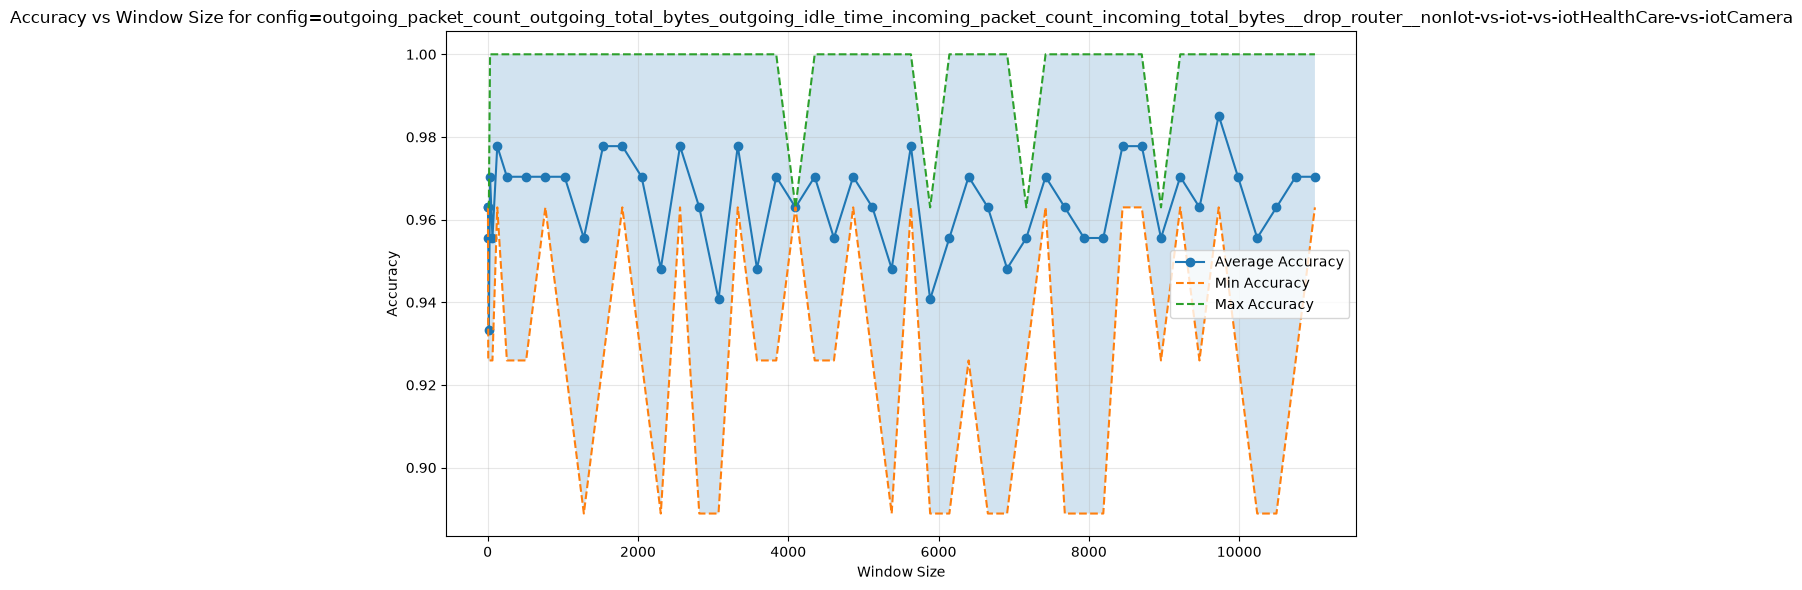

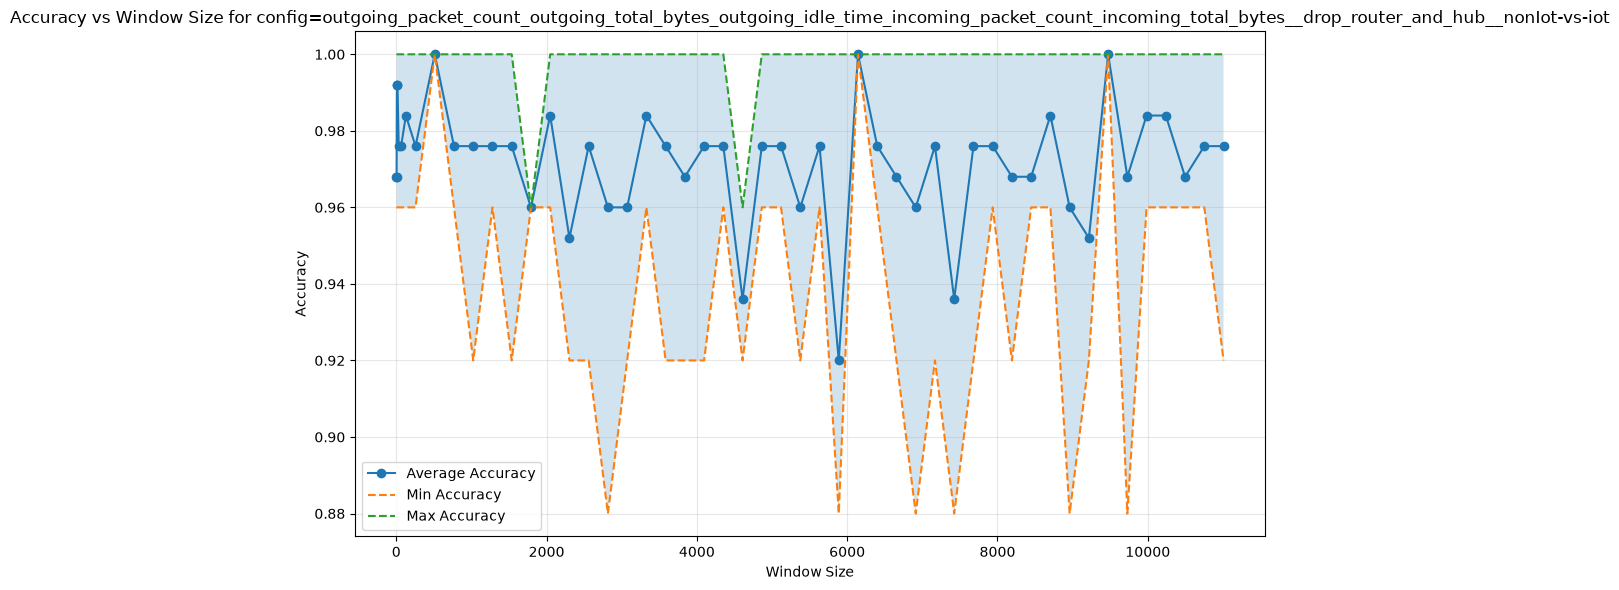

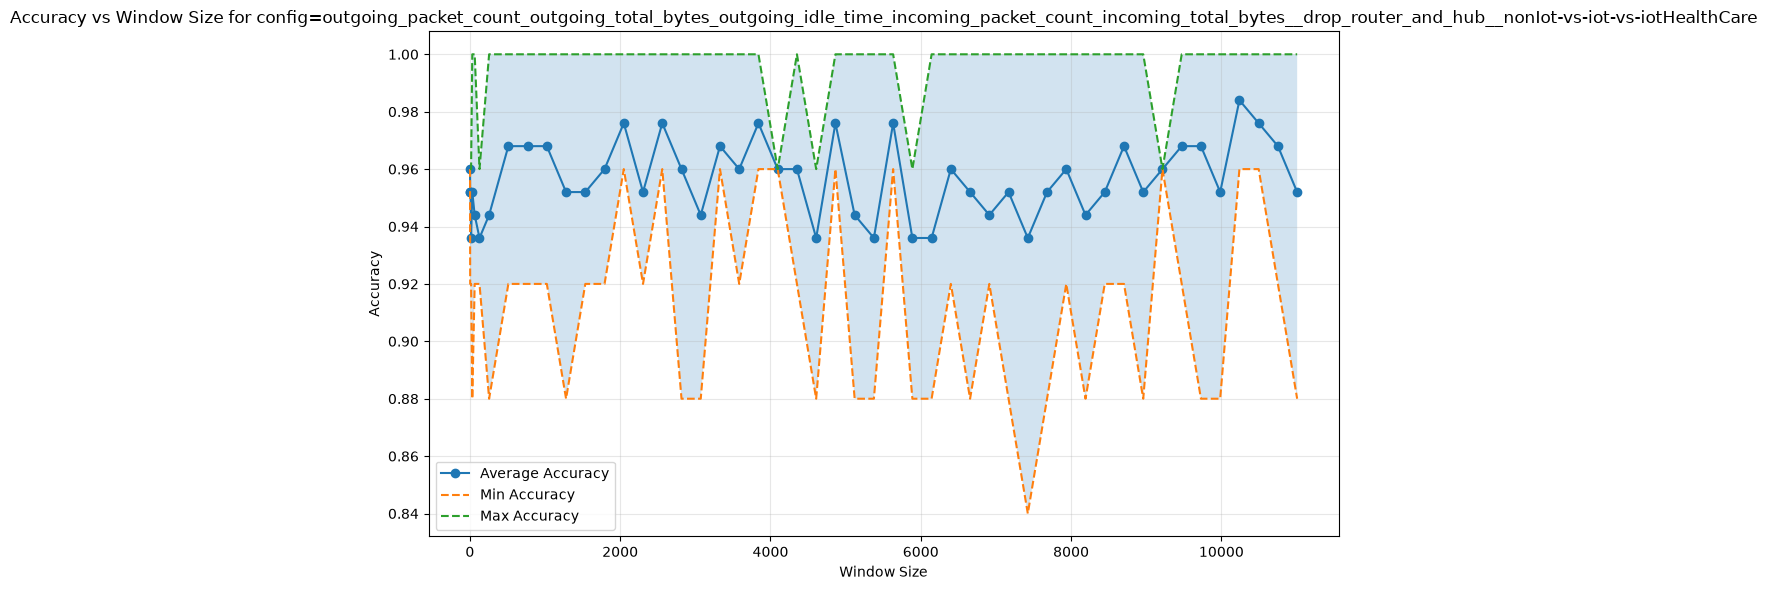

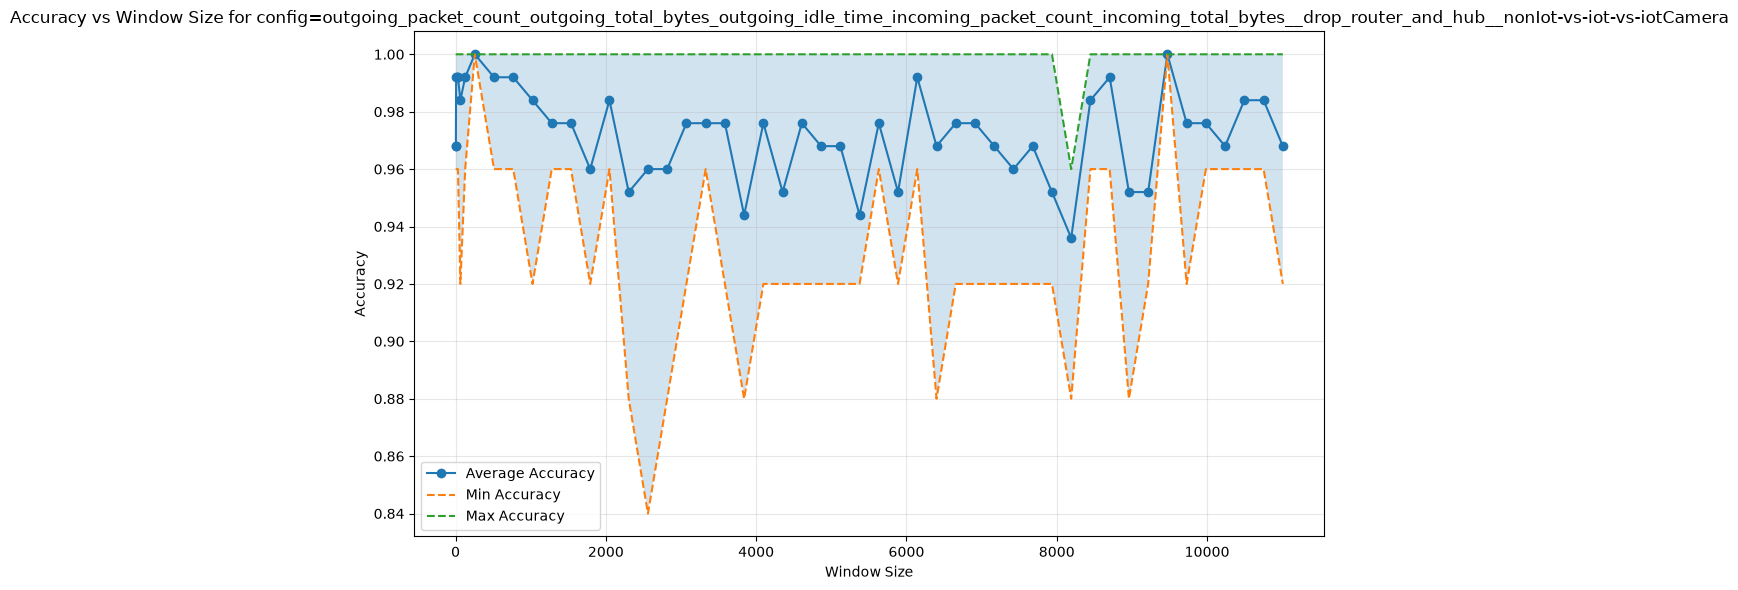

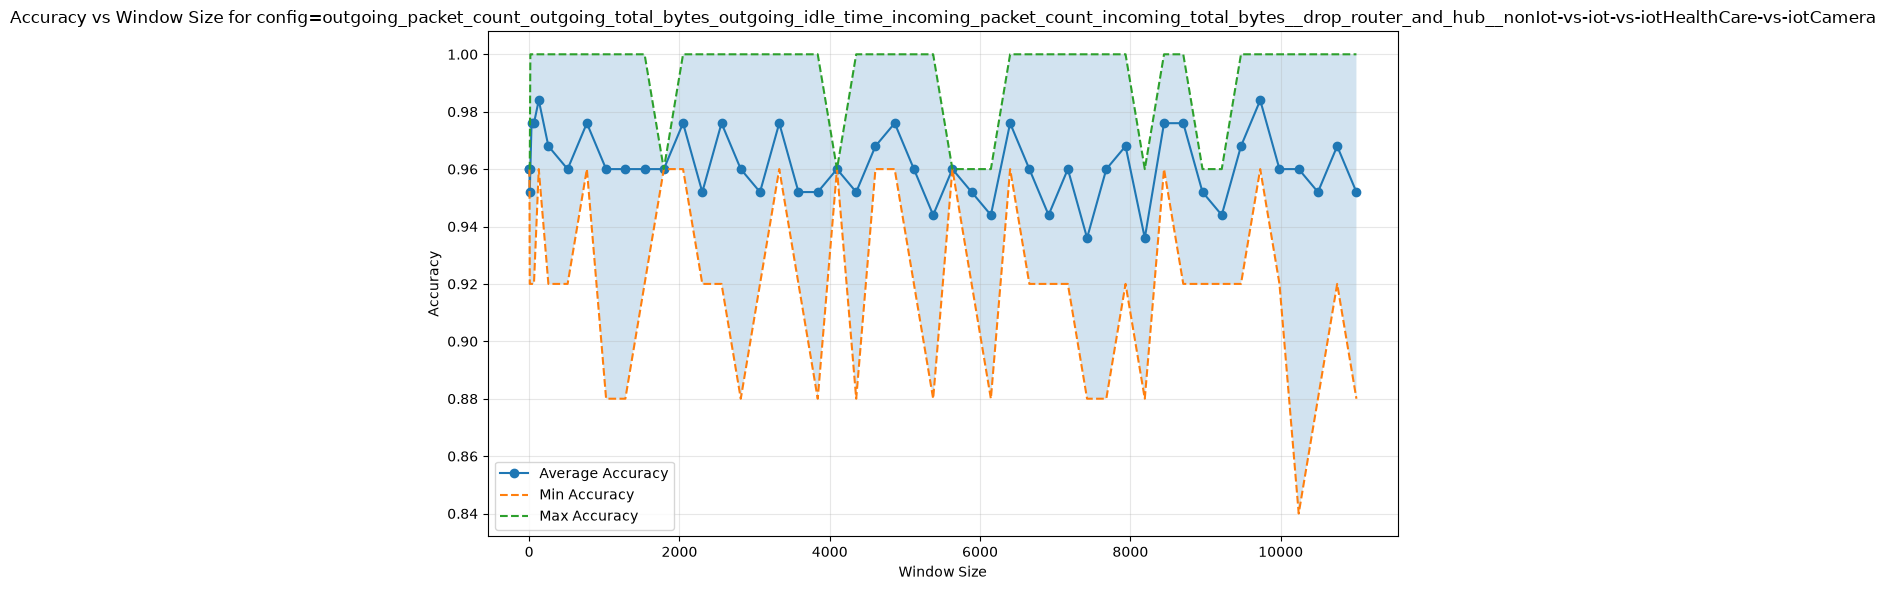

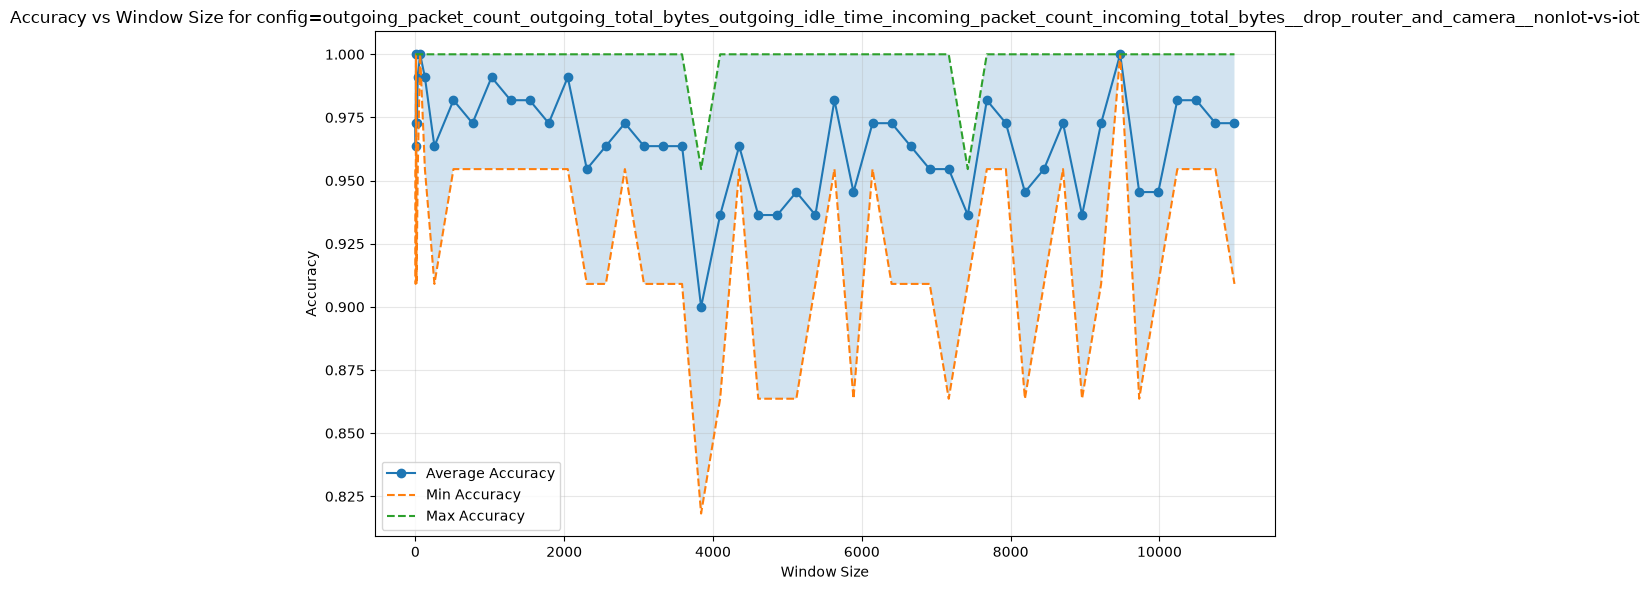

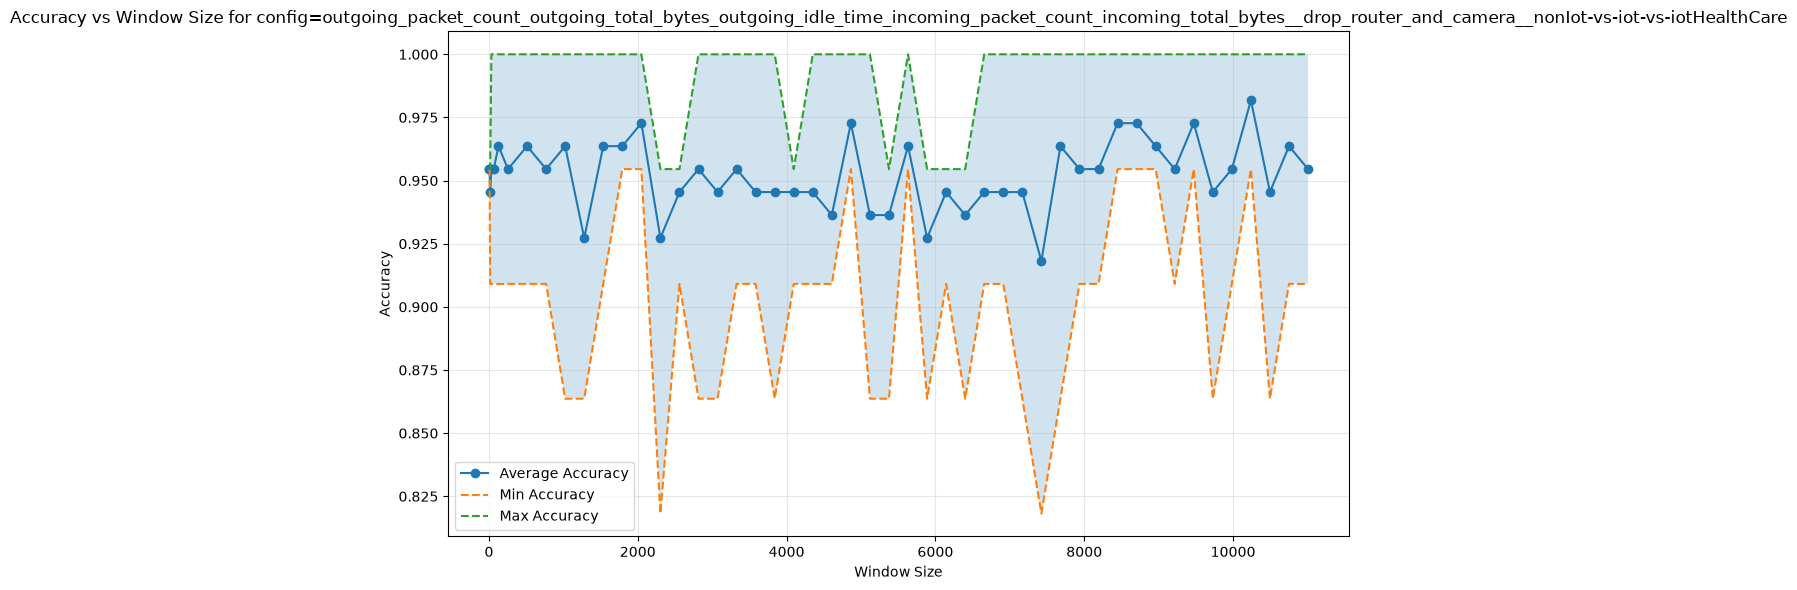

In [1]:
from __future__ import annotations

import sys
from copy import deepcopy
from pathlib import Path
from typing import Dict, List, Set, Tuple
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler


# %%

# ============================================================
# Environment / paths
# ============================================================
package_root = str(Path.cwd().parent)
if package_root not in sys.path:
    sys.path.append(package_root)

pd.set_option("display.max_colwidth", None)

DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"
EXTRACTED_DATA_FOLDER = DATASET1 + "/all_traffic.parquet"
DEVICE_TO_BE_INCLUDE = DATASET1 + "/device_to_be_include.json"
PERFORMANCE_EXPORT_FOLDER = "./performance"

MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
MAPPING_LIST_2 = f"{DEVICE_MAPPING_FOLDER}/{DATASET2}/list_of_devices_processed.csv"
INPUT_1 = f"{INPUT_FOLDER}/{DATASET1}"
INPUT_2 = f"{INPUT_FOLDER}/{DATASET2}"


# %%

# ============================================================
# Load data
# ============================================================
with open(DEVICE_TO_BE_INCLUDE, "r") as f:
    device_dict_1 = json.load(f)

all_data = pd.read_parquet(EXTRACTED_DATA_FOLDER)

# No full-data copy is needed because the optimized feature builder
# never mutates the input DataFrame.
process_df = all_data


# %%

# ============================================================
# Constants
# ============================================================
WINDOW_SECONDS = 60

INCOMING_FEATURES = [
    "incoming_packet_count",
    "incoming_total_bytes",
    "incoming_idle_time",
]

OUTGOING_FEATURES = [
    "outgoing_packet_count",
    "outgoing_total_bytes",
    "outgoing_idle_time",
]

LABEL_COLUMN = "is_iot_device"
KSPLITS = 5
RANDOM_SEED = 42


# %%

# ============================================================
# Device-dropping strategies
# ============================================================
def get_all_devices(list_of_devices: List[str]) -> Set[str]:
    return set(list_of_devices)


def drop_router(list_of_devices: List[str]) -> Set[str]:
    router_devices = {"14:cc:20:51:33:ea"}
    return set(list_of_devices) - router_devices


def drop_router_and_hub(list_of_devices: List[str]) -> Set[str]:
    router_devices = {"14:cc:20:51:33:ea"}
    hub_devices = {
        "d0:52:a8:00:67:5e",
        "44:65:0d:56:cc:d3",
    }
    return set(list_of_devices) - router_devices - hub_devices


def drop_router_and_camera(list_of_devices: List[str]) -> Set[str]:
    router_devices = {"14:cc:20:51:33:ea"}
    camera_devices = {
        "70:ee:50:18:34:43",
        "30:8c:fb:2f:e4:b2",
        "00:16:6c:ab:6b:88",
        "f4:f2:6d:93:51:f1",
        "00:62:6e:51:27:2e",
    }
    return set(list_of_devices) - router_devices - camera_devices


dropping_strategies = {
    "no_dropping": get_all_devices,
    "drop_router": drop_router,
    "drop_router_and_hub": drop_router_and_hub,
    "drop_router_and_camera": drop_router_and_camera,
}


# %%

# ============================================================
# Labeling strategies
# ============================================================
def label_2_class(
    features: pd.DataFrame,
    device_mapping: Dict[str, Dict[str, str]],
) -> pd.DataFrame:
    unknown_macs = set(features["mac"]) - set(device_mapping)
    if unknown_macs:
        raise KeyError(
            f"MAC addresses not found in device_mapping: {unknown_macs}"
        )

    res = features.copy()
    res["is_iot_device"] = res["mac"].map(
        lambda x: device_mapping[x]["is_iot_device"]
    )
    res["device_type"] = res["mac"].map(
        lambda x: device_mapping[x]["device_type"]
    )
    res["vendor"] = res["mac"].map(
        lambda x: device_mapping[x]["vendor"]
    )
    return res


def label_3_class_health_care_device_type_3(
    features: pd.DataFrame,
    device_mapping: Dict[str, Dict[str, str]],
) -> pd.DataFrame:
    unknown_macs = set(features["mac"]) - set(device_mapping)
    if unknown_macs:
        raise KeyError(
            f"MAC addresses not found in device_mapping: {unknown_macs}"
        )

    device_mapping_copy = deepcopy(device_mapping)
    health_monitor_devices = {
        "74:6a:89:00:2e:25",
        "18:b4:30:25:be:e4",
        "00:24:e4:1b:6f:96",
    }

    for mac in device_mapping_copy:
        if device_mapping_copy[mac]["is_iot_device"] == 0:
            device_mapping_copy[mac]["is_iot_device"] = 1
        else:
            if mac in health_monitor_devices:
                device_mapping_copy[mac]["is_iot_device"] = 3
            else:
                device_mapping_copy[mac]["is_iot_device"] = 2

    res = features.copy()
    res["is_iot_device"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["is_iot_device"]
    )
    res["device_type"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["device_type"]
    )
    res["vendor"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["vendor"]
    )
    return res


def label_3_class_camera_device_type_3(
    features: pd.DataFrame,
    device_mapping: Dict[str, Dict[str, str]],
) -> pd.DataFrame:
    unknown_macs = set(features["mac"]) - set(device_mapping)
    if unknown_macs:
        raise KeyError(
            f"MAC addresses not found in device_mapping: {unknown_macs}"
        )

    device_mapping_copy = deepcopy(device_mapping)
    camera_set = {
        "30:8c:fb:b6:ea:45",
        "00:62:6e:51:27:2e",
        "e8:ab:fa:19:de:4f",
        "30:8c:fb:2f:e4:b2",
        "00:16:6c:ab:6b:88",
        "f4:f2:6d:93:51:f1",
        "70:ee:50:18:34:43",
    }

    for mac in device_mapping_copy:
        if device_mapping_copy[mac]["is_iot_device"] == 0:
            device_mapping_copy[mac]["is_iot_device"] = 1
        else:
            if mac in camera_set:
                device_mapping_copy[mac]["is_iot_device"] = 3
            else:
                device_mapping_copy[mac]["is_iot_device"] = 2

    res = features.copy()
    res["is_iot_device"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["is_iot_device"]
    )
    res["device_type"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["device_type"]
    )
    res["vendor"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["vendor"]
    )
    return res


def label_4_class_camera_and_health_care(
    features: pd.DataFrame,
    device_mapping: Dict[str, Dict[str, str]],
) -> pd.DataFrame:
    unknown_macs = set(features["mac"]) - set(device_mapping)
    if unknown_macs:
        raise KeyError(
            f"MAC addresses not found in device_mapping: {unknown_macs}"
        )

    device_mapping_copy = deepcopy(device_mapping)

    health_monitor_devices = {
        "74:6a:89:00:2e:25",
        "18:b4:30:25:be:e4",
        "00:24:e4:1b:6f:96",
    }

    camera_set = {
        "30:8c:fb:b6:ea:45",
        "00:62:6e:51:27:2e",
        "e8:ab:fa:19:de:4f",
        "30:8c:fb:2f:e4:b2",
        "00:16:6c:ab:6b:88",
        "f4:f2:6d:93:51:f1",
        "70:ee:50:18:34:43",
    }

    for mac in device_mapping_copy:
        if device_mapping_copy[mac]["is_iot_device"] == 0:
            device_mapping_copy[mac]["is_iot_device"] = 1
        else:
            if mac in health_monitor_devices:
                device_mapping_copy[mac]["is_iot_device"] = 3
            elif mac in camera_set:
                device_mapping_copy[mac]["is_iot_device"] = 4
            else:
                device_mapping_copy[mac]["is_iot_device"] = 2

    res = features.copy()
    res["is_iot_device"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["is_iot_device"]
    )
    res["device_type"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["device_type"]
    )
    res["vendor"] = res["mac"].map(
        lambda x: device_mapping_copy[x]["vendor"]
    )
    return res


labeling_strategies = {
    "nonIot-vs-iot": (
        label_2_class,
        [0, 1],
    ),
    "nonIot-vs-iot-vs-iotHealthCare": (
        label_3_class_health_care_device_type_3,
        [1, 2, 3],
    ),
    "nonIot-vs-iot-vs-iotCamera": (
        label_3_class_camera_device_type_3,
        [1, 2, 3],
    ),
    "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera": (
        label_4_class_camera_and_health_care,
        [1, 2, 3, 4],
    ),
}


# ============================================================
# Precompute tiny per-device label/metadata lookups once.
# This avoids repeatedly relabeling/copying the full feature table.
# ============================================================
device_type_lookup = {
    mac: info["device_type"]
    for mac, info in device_dict_1.items()
}

vendor_lookup = {
    mac: info["vendor"]
    for mac, info in device_dict_1.items()
}

_device_rows = pd.DataFrame({"mac": list(device_dict_1.keys())})

label_lookup_by_strategy = {}
for strategy_name, (label_func, _) in labeling_strategies.items():
    labeled_devices = label_func(
        features=_device_rows,
        device_mapping=device_dict_1,
    )
    label_lookup_by_strategy[strategy_name] = (
        labeled_devices
        .set_index("mac")[LABEL_COLUMN]
        .to_dict()
    )


# ============================================================
# Feature extraction optimization
#
# The raw packet table is aggregated only ONCE at the greatest
# common divisor of all requested windows (2 seconds here).
# Larger windows are then obtained by rolling up those base buckets.
# ============================================================
def precompute_base_directional_features(
    raw_df: pd.DataFrame,
    device_to_be_include: Set[str],
    base_window: int,
) -> dict:
    if base_window <= 0:
        raise ValueError("base_window must be greater than 0")

    device_to_be_include = set(device_to_be_include)

    capture_starts = (
        raw_df
        .groupby(
            "capture_id",
            sort=False,
            observed=True,
        )["frame.time_epoch"]
        .min()
    )

    capture_order = pd.Index(
        raw_df["capture_id"]
        .dropna()
        .drop_duplicates()
    )

    capture_start_per_row = (
        raw_df
        .groupby(
            "capture_id",
            sort=False,
            observed=True,
        )["frame.time_epoch"]
        .transform("min")
    )

    base_window_values = (
        (
            raw_df["frame.time_epoch"]
            - capture_start_per_row
        )
        // base_window
    ).astype("int32")

    # ----------------------------
    # Outgoing base aggregation
    # ----------------------------
    outgoing_mask = raw_df["eth.src"].isin(device_to_be_include)

    outgoing_source = raw_df.loc[
        outgoing_mask,
        [
            "capture_id",
            "eth.src",
            "frame.len",
            "frame.time_epoch",
        ],
    ].copy()

    outgoing_source["base_window"] = (
        base_window_values.loc[outgoing_mask].to_numpy()
    )

    outgoing_source = outgoing_source.rename(
        columns={"eth.src": "device"}
    )

    outgoing = (
        outgoing_source
        .groupby(
            ["capture_id", "base_window", "device"],
            sort=False,
            observed=True,
        )
        .agg(
            outgoing_packet_count=("frame.len", "size"),
            outgoing_total_bytes=("frame.len", "sum"),
            outgoing_first_timestamp=("frame.time_epoch", "min"),
            outgoing_last_timestamp=("frame.time_epoch", "max"),
        )
        .reset_index()
    )

    del outgoing_source

    # ----------------------------
    # Incoming base aggregation
    # ----------------------------
    incoming_mask = raw_df["eth.dst"].isin(device_to_be_include)

    incoming_source = raw_df.loc[
        incoming_mask,
        [
            "capture_id",
            "eth.dst",
            "frame.len",
            "frame.time_epoch",
        ],
    ].copy()

    incoming_source["base_window"] = (
        base_window_values.loc[incoming_mask].to_numpy()
    )

    incoming_source = incoming_source.rename(
        columns={"eth.dst": "device"}
    )

    incoming = (
        incoming_source
        .groupby(
            ["capture_id", "base_window", "device"],
            sort=False,
            observed=True,
        )
        .agg(
            incoming_packet_count=("frame.len", "size"),
            incoming_total_bytes=("frame.len", "sum"),
            incoming_first_timestamp=("frame.time_epoch", "min"),
            incoming_last_timestamp=("frame.time_epoch", "max"),
        )
        .reset_index()
    )

    del incoming_source

    return {
        "base_window": base_window,
        "capture_starts": capture_starts,
        "capture_order": capture_order,
        "outgoing": outgoing,
        "incoming": incoming,
    }


def _roll_up_direction(
    base_df: pd.DataFrame,
    factor: int,
    direction: str,
) -> pd.DataFrame:
    if factor == 1:
        return base_df.rename(
            columns={"base_window": "window"}
        )

    target_window = (
        base_df["base_window"] // factor
    ).astype("int32")
    target_window = target_window.rename("window")

    if direction == "outgoing":
        return (
            base_df
            .groupby(
                [
                    base_df["capture_id"],
                    target_window,
                    base_df["device"],
                ],
                sort=False,
                observed=True,
            )
            .agg(
                outgoing_packet_count=(
                    "outgoing_packet_count",
                    "sum",
                ),
                outgoing_total_bytes=(
                    "outgoing_total_bytes",
                    "sum",
                ),
                outgoing_first_timestamp=(
                    "outgoing_first_timestamp",
                    "min",
                ),
                outgoing_last_timestamp=(
                    "outgoing_last_timestamp",
                    "max",
                ),
            )
            .reset_index()
        )

    if direction == "incoming":
        return (
            base_df
            .groupby(
                [
                    base_df["capture_id"],
                    target_window,
                    base_df["device"],
                ],
                sort=False,
                observed=True,
            )
            .agg(
                incoming_packet_count=(
                    "incoming_packet_count",
                    "sum",
                ),
                incoming_total_bytes=(
                    "incoming_total_bytes",
                    "sum",
                ),
                incoming_first_timestamp=(
                    "incoming_first_timestamp",
                    "min",
                ),
                incoming_last_timestamp=(
                    "incoming_last_timestamp",
                    "max",
                ),
            )
            .reset_index()
        )

    raise ValueError(
        "direction must be either 'outgoing' or 'incoming'"
    )


def build_feature_from_base(
    base_cache: dict,
    window: int,
) -> pd.DataFrame:
    if window <= 0:
        raise ValueError("window must be greater than 0")

    base_window = base_cache["base_window"]

    if window % base_window != 0:
        raise ValueError(
            f"window={window} must be divisible by "
            f"base_window={base_window}"
        )

    output_columns = [
        "capture_id",
        "window",
        "mac",
        "outgoing_packet_count",
        "outgoing_total_bytes",
        "outgoing_idle_time",
        "incoming_packet_count",
        "incoming_total_bytes",
        "incoming_idle_time",
    ]

    factor = window // base_window

    outgoing = _roll_up_direction(
        base_df=base_cache["outgoing"],
        factor=factor,
        direction="outgoing",
    )

    incoming = _roll_up_direction(
        base_df=base_cache["incoming"],
        factor=factor,
        direction="incoming",
    )

    features = outgoing.merge(
        incoming,
        on=["capture_id", "window", "device"],
        how="outer",
        sort=False,
    )

    if features.empty:
        return pd.DataFrame(columns=output_columns)

    # Preserve the same capture ordering as the original raw table,
    # then sort device/window exactly as before.
    capture_order_map = pd.Series(
        np.arange(
            len(base_cache["capture_order"]),
            dtype="int32",
        ),
        index=base_cache["capture_order"],
    )

    features["_capture_order"] = (
        features["capture_id"].map(capture_order_map)
    )

    features = (
        features
        .sort_values(
            ["_capture_order", "device", "window"],
            kind="mergesort",
        )
        .drop(columns="_capture_order")
        .reset_index(drop=True)
    )

    integer_columns = [
        "outgoing_packet_count",
        "outgoing_total_bytes",
        "incoming_packet_count",
        "incoming_total_bytes",
    ]

    features[integer_columns] = (
        features[integer_columns]
        .fillna(0)
    )

    capture_starts = (
        base_cache["capture_starts"]
        .reindex(features["capture_id"])
        .to_numpy()
    )

    features["window_end_timestamp"] = (
        capture_starts
        + (features["window"].to_numpy() + 1) * window
    )

    group_keys = [
        features["capture_id"],
        features["device"],
    ]

    # ----------------------------
    # Outgoing idle time
    # ----------------------------
    outgoing_ffill = (
        features
        .groupby(
            ["capture_id", "device"],
            sort=False,
            observed=True,
        )["outgoing_last_timestamp"]
        .ffill()
    )

    previous_outgoing_last_timestamp = (
        outgoing_ffill
        .groupby(
            group_keys,
            sort=False,
            observed=True,
        )
        .shift()
    )

    outgoing_reference_time = (
        features["outgoing_first_timestamp"]
        .fillna(features["window_end_timestamp"])
    )

    features["outgoing_idle_time"] = (
        outgoing_reference_time
        - previous_outgoing_last_timestamp.fillna(
            pd.Series(
                capture_starts,
                index=features.index,
            )
        )
    )

    # ----------------------------
    # Incoming idle time
    # ----------------------------
    incoming_ffill = (
        features
        .groupby(
            ["capture_id", "device"],
            sort=False,
            observed=True,
        )["incoming_last_timestamp"]
        .ffill()
    )

    previous_incoming_last_timestamp = (
        incoming_ffill
        .groupby(
            group_keys,
            sort=False,
            observed=True,
        )
        .shift()
    )

    incoming_reference_time = (
        features["incoming_first_timestamp"]
        .fillna(features["window_end_timestamp"])
    )

    features["incoming_idle_time"] = (
        incoming_reference_time
        - previous_incoming_last_timestamp.fillna(
            pd.Series(
                capture_starts,
                index=features.index,
            )
        )
    )

    features = features.rename(
        columns={"device": "mac"}
    )

    features = features[output_columns]

    features[integer_columns] = (
        features[integer_columns]
        .astype("int64")
    )

    features[
        [
            "outgoing_idle_time",
            "incoming_idle_time",
        ]
    ] = features[
        [
            "outgoing_idle_time",
            "incoming_idle_time",
        ]
    ].astype("float64")

    return features


# %%

# ============================================================
# Capture-separated repeated split
# ============================================================
def device_capture_repeated_split(
    df: pd.DataFrame,
    set_of_devices_to_be_classified,
    n_splits: int = 5,
    random_state: int = 42,
):
    target_devices = set_of_devices_to_be_classified

    target_mask = df["mac"].isin(target_devices).to_numpy()
    target_positions = np.flatnonzero(target_mask)

    work_df = df.iloc[target_positions][
        ["mac", "capture_id"]
    ].copy()

    existing_devices = set(work_df["mac"].unique())
    missing_devices = target_devices - existing_devices

    if missing_devices:
        raise ValueError(
            f"Devices not found in dataframe: {missing_devices}"
        )

    device_captures = (
        work_df
        .drop_duplicates()
        .reset_index(drop=True)
    )

    capture_counts = (
        device_captures
        .groupby("mac", observed=True)
        .size()
    )

    insufficient = capture_counts[capture_counts < 2]

    if not insufficient.empty:
        raise ValueError(
            "These devices have fewer than 2 capture_ids, "
            "so capture-level train/validation separation is impossible:\n"
            f"{insufficient}"
        )

    rng = np.random.default_rng(random_state)

    captures_by_device = {}

    for device, group in device_captures.groupby(
        "mac",
        observed=True,
        sort=False,
    ):
        captures = group["capture_id"].to_numpy().copy()
        rng.shuffle(captures)
        captures_by_device[device] = captures

    folds = []

    row_devices = work_df["mac"].to_numpy()
    row_captures = work_df["capture_id"].to_numpy()

    for fold_idx in range(n_splits):
        val_capture_by_device = {
            device: captures[fold_idx % len(captures)]
            for device, captures in captures_by_device.items()
        }

        val_mask = np.zeros(
            len(work_df),
            dtype=bool,
        )

        for device, val_capture in val_capture_by_device.items():
            val_mask |= (
                (row_devices == device)
                & (row_captures == val_capture)
            )

        folds.append(
            {
                "fold": fold_idx,
                "train_iloc": target_positions[~val_mask],
                "val_iloc": target_positions[val_mask],
                "val_capture_by_device": val_capture_by_device,
            }
        )

    return folds


# %%

def evaluate_device_predictions(
    val_df: pd.DataFrame,
    set_of_devices_to_be_classified: set,
    device_dict: dict,
    label_column: str,
    class_labels: list,
    label_function: callable
) -> Tuple[dict, pd.DataFrame]:

    expected_devices = set_of_devices_to_be_classified
    actual_devices = set(val_df["mac"].unique())

    if actual_devices != expected_devices:
        missing = expected_devices - actual_devices
        unexpected = actual_devices - expected_devices

        raise ValueError(
            f"Device mismatch.\n"
            f"Missing from validation: {missing}\n"
            f"Unexpected in validation: {unexpected}"
        )

    if val_df["prediction_each_window"].isna().any():
        raise ValueError(
            "prediction_each_window contains missing values."
        )

    prediction_values = set(
        val_df["prediction_each_window"].unique()
    )

    invalid_predictions = (
        prediction_values - set(class_labels)
    )

    if invalid_predictions:
        raise ValueError(
            f"Found predictions not included in class_labels: "
            f"{invalid_predictions}"
        )

    evaluation = (
        val_df
        .groupby("mac", observed=True)
        ["prediction_each_window"]
        .agg(
            total_predictions="size",

            prediction_counts=lambda x: (
                x.value_counts()
                .reindex(
                    class_labels,
                    fill_value=0,
                )
                .to_dict()
            ),

            aggregated_prediction=lambda x: (
                x.value_counts()
                .reindex(
                    class_labels,
                    fill_value=0,
                )
                .idxmax()
            ),
        )
        .reset_index()
    )

    evaluation = label_function(
        features=evaluation,
        device_mapping=device_dict,
    )

    true_labels = set(
        evaluation[label_column].unique()
    )

    invalid_true_labels = (
        true_labels - set(class_labels)
    )

    if invalid_true_labels:
        raise ValueError(
            f"Found true labels not included in class_labels: "
            f"{invalid_true_labels}"
        )

    accuracy = accuracy_score(
        evaluation[label_column],
        evaluation["aggregated_prediction"],
    )

    misclassified_mask = (
        evaluation[label_column]
        != evaluation["aggregated_prediction"]
    )

    misclassified_devices = (
        evaluation.loc[
            misclassified_mask,
            "mac"
        ]
        .to_list()
    )

    evaluation = evaluation.rename(
        columns={"is_iot_device": "true_label"}
    )

    metrics = {
        "accuracy": accuracy,
        "device_count": len(evaluation),
        "correct_count": (~misclassified_mask).sum(),
        "misclassified_count": misclassified_mask.sum(),
        "misclassified_devices": misclassified_devices,
    }

    return metrics, evaluation


# %%

# ============================================================
# Feature combinations
# ============================================================
feature_combinations = []

for i in range(len(INCOMING_FEATURES) - 1):
    feature_combinations.append(
        OUTGOING_FEATURES + INCOMING_FEATURES[:i + 1]
    )


# %%

# ============================================================
# Window sizes
# ============================================================
window_size = [2, 4, 8, 16, 32, 64, 128, 256]

while window_size[-1] < 10800:
    window_size.append(window_size[-1] + 256)


# %%

# ============================================================
# Model
# ============================================================
def create_decision_tree(
    random_seed: int = 42,
) -> DecisionTreeClassifier:
    return DecisionTreeClassifier(
        criterion="gini",
        splitter="best",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,
        max_features=None,
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        class_weight="balanced",
        random_state=random_seed,
    )


# %%

# ============================================================
# Configuration records
# ============================================================
all_configs = {}

for combo in feature_combinations:
    for dropping_strategy_name, dropping_strategy_func in dropping_strategies.items():
        for labeling_strategy_name, labeling_strategy_data in labeling_strategies.items():
            if (
                dropping_strategy_name == "drop_router_and_camera"
                and labeling_strategy_name
                in {
                    "nonIot-vs-iot-vs-iotCamera",
                    "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera",
                }
            ):
                continue

            config_key = (
                "_".join(combo)
                + f"__{dropping_strategy_name}"
                + f"__{labeling_strategy_name}"
            )

            all_configs[config_key] = {
                "config": {
                    "feature_combination": combo,
                    "dropping_strategy": dropping_strategy_name,
                    "labeling_strategy": labeling_strategy_name,
                },
                "metrics": [],
                "evaluations": [],
            }


set_all_devices = set(device_dict_1.keys())
all_device_list = list(device_dict_1.keys())

# Compute each device subset once, not once per window/configuration.
devices_by_dropping_strategy = {
    strategy_name: strategy_func(all_device_list)
    for strategy_name, strategy_func in dropping_strategies.items()
}

# Unique model feature order used for one shared NumPy matrix per window.
model_feature_columns = list(
    dict.fromkeys(
        feature
        for combo in feature_combinations
        for feature in combo
    )
)

model_feature_index = {
    feature: i
    for i, feature in enumerate(model_feature_columns)
}

combo_column_indices = {
    tuple(combo): np.array(
        [model_feature_index[feature] for feature in combo],
        dtype=np.intp,
    )
    for combo in feature_combinations
}


# %%

# ============================================================
# Precompute raw packet aggregation ONCE
# ============================================================
BASE_WINDOW_SECONDS = int(
    np.gcd.reduce(
        np.asarray(window_size, dtype=np.int64)
    )
)

print(
    f"Precomputing base directional features at "
    f"{BASE_WINDOW_SECONDS}-second resolution..."
)

base_feature_cache = precompute_base_directional_features(
    raw_df=process_df,
    device_to_be_include=set_all_devices,
    base_window=BASE_WINDOW_SECONDS,
)


# %%

# ============================================================
# Main experiment loop
# ============================================================
for window in window_size:
    print(f"Computing for window {window}.....")

    features_window = build_feature_from_base(
        base_cache=base_feature_cache,
        window=window,
    )

    training_and_validation_folds = device_capture_repeated_split(
        df=features_window,
        set_of_devices_to_be_classified=set_all_devices,
        n_splits=KSPLITS,
        random_state=RANDOM_SEED,
    )

    # One feature matrix for the whole window.
    # DecisionTreeClassifier internally works with float32,
    # so converting once here avoids repeated conversions.
    feature_matrix = features_window[
        model_feature_columns
    ].to_numpy(
        dtype=np.float32,
        copy=False,
    )

    mac_values = features_window["mac"].to_numpy(
        copy=False
    )

    # Build each label vector once per window.
    labels_by_strategy = {}

    for labeling_strategy_name in labeling_strategies:
        label_series = features_window["mac"].map(
            label_lookup_by_strategy[labeling_strategy_name]
        )

        if label_series.isna().any():
            unknown = set(
                features_window.loc[
                    label_series.isna(),
                    "mac",
                ]
            )
            raise KeyError(
                "MAC addresses not found in label lookup: "
                f"{unknown}"
            )

        labels_by_strategy[labeling_strategy_name] = (
            label_series.to_numpy(copy=False)
        )

    # Build row masks once per dropping strategy.
    include_masks = {
        dropping_strategy_name: (
            features_window["mac"]
            .isin(device_to_be_include)
            .to_numpy()
        )
        for dropping_strategy_name, device_to_be_include
        in devices_by_dropping_strategy.items()
    }

    # Pre-filter fold indices once per dropping strategy.
    filtered_folds = {}

    for dropping_strategy_name, include_mask in include_masks.items():
        strategy_folds = []

        for fold in training_and_validation_folds:
            original_train_iloc = fold["train_iloc"]
            original_val_iloc = fold["val_iloc"]

            train_iloc = original_train_iloc[
                include_mask[original_train_iloc]
            ]

            val_iloc = original_val_iloc[
                include_mask[original_val_iloc]
            ]

            strategy_folds.append(
                {
                    "fold": fold["fold"],
                    "train_iloc": train_iloc,
                    "val_iloc": val_iloc,
                }
            )

        filtered_folds[dropping_strategy_name] = strategy_folds

    # --------------------------------------------------------
    # Train/evaluate
    # --------------------------------------------------------
    for dropping_strategy_name in dropping_strategies:
        device_to_be_include = (
            devices_by_dropping_strategy[
                dropping_strategy_name
            ]
        )

        for combo in feature_combinations:
            column_indices = combo_column_indices[
                tuple(combo)
            ]

            # Fold is outside labeling strategy so X_train/X_val
            # are created once and reused across all label schemes.
            for fold in filtered_folds[dropping_strategy_name]:
                train_iloc = fold["train_iloc"]
                val_iloc = fold["val_iloc"]

                X_train = feature_matrix[
                    np.ix_(train_iloc, column_indices)
                ]

                X_val = feature_matrix[
                    np.ix_(val_iloc, column_indices)
                ]

                # Keep the original preprocessing behavior, but only fit
                # the scaler once for this window + dropping strategy +
                # feature combination + fold. The scaled matrices are
                # reused across all labeling strategies because X is
                # identical; only y changes.
                scaler = StandardScaler()
                X_train_scaled = scaler.fit_transform(X_train)
                X_val_scaled = scaler.transform(X_val)

                val_macs = mac_values[val_iloc]

                for labeling_strategy_name, (
                    labeling_strategy_func,
                    all_classes,
                ) in labeling_strategies.items():
                    if (
                        dropping_strategy_name
                        == "drop_router_and_camera"
                        and labeling_strategy_name
                        in {
                            "nonIot-vs-iot-vs-iotCamera",
                            "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera",
                        }
                    ):
                        continue

                    config_key = (
                        "_".join(combo)
                        + f"__{dropping_strategy_name}"
                        + f"__{labeling_strategy_name}"
                    )

                    y_all = labels_by_strategy[
                        labeling_strategy_name
                    ]

                    y_train = y_all[train_iloc]

                    model = create_decision_tree(
                        random_seed=RANDOM_SEED
                    )

                    # No undersampling.
                    # StandardScaler is intentionally retained so this
                    # experiment remains preprocessing-compatible with
                    # the previous runs.
                    model.fit(X_train_scaled, y_train)
                    y_pred = model.predict(X_val_scaled)

                    # Evaluation only needs MAC + prediction.
                    # Do not copy the entire validation feature frame.
                    val_prediction_df = pd.DataFrame(
                        {
                            "mac": val_macs,
                            "prediction_each_window": y_pred,
                        }
                    )

                    metrics, evaluation_detail = evaluate_device_predictions(
                        val_df=val_prediction_df,
                        set_of_devices_to_be_classified=device_to_be_include,
                        device_dict=device_dict_1,
                        label_column=LABEL_COLUMN,
                        class_labels=all_classes,
                        label_function=labeling_strategy_func
                    )

                    metrics["fold"] = fold["fold"]
                    metrics["window"] = window

                    evaluation_detail["fold"] = fold["fold"]
                    evaluation_detail["window"] = window

                    all_configs[config_key]["metrics"].append(
                        metrics
                    )
                    all_configs[config_key]["evaluations"].append(
                        evaluation_detail
                    )


# %%

# ============================================================
# Add class labels into saved configuration
# ============================================================
for config in all_configs:
    _, class_labels = labeling_strategies[
        all_configs[config]["config"]["labeling_strategy"]
    ]

    all_configs[config]["config"]["class_labels"] = (
        class_labels.copy()
    )


# %%

# ============================================================
# Plot confusion matrices
# ============================================================
def plot_confusion_matrices(
    evaluations_df,
    config_path,
    class_labels=(1, 2, 3),
):
    y_true = evaluations_df["true_label"]
    y_pred = evaluations_df["aggregated_prediction"]

    # --------------------------------------------------
    # 1. Raw-count confusion matrix
    # --------------------------------------------------
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=class_labels,
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels,
    )

    disp.plot(
        values_format="d"
    )

    plt.title("Device-Level Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()

    plt.savefig(
        f"{config_path}/confusion_matrix.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.close()

    # --------------------------------------------------
    # 2. Normalized confusion matrix
    # --------------------------------------------------
    cm_normalized = confusion_matrix(
        y_true,
        y_pred,
        labels=class_labels,
        normalize="true",
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm_normalized,
        display_labels=class_labels,
    )

    disp.plot(
        values_format=".2f"
    )

    plt.title("Normalized Device-Level Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()

    plt.savefig(
        f"{config_path}/confusion_matrix_normalized.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.close()


# %%

# ============================================================
# Export -- intentionally kept the same as your notebook
# ============================================================
for config in all_configs:
    config_path = PERFORMANCE_EXPORT_FOLDER + "/" + config
    Path(config_path).mkdir(parents=True, exist_ok=True)
    metrics_df = pd.DataFrame(all_configs[config]["metrics"])
    evaluations_df = pd.concat(all_configs[config]["evaluations"])

    # Write these two config into csv files
    metrics_df.to_csv(f"{config_path}/performance.csv", index=False)
    evaluations_df.to_csv(f"{config_path}/detail_performance.csv", index=False)
    with open(f"{config_path}/config.json", "w") as f:
        json.dump(
            all_configs[config]["config"],
            f,
            indent=4,
        )

    accuracy_summary = (
        metrics_df
        .groupby("window")["accuracy"]
        .agg(
            avg_accuracy="mean",
            min_accuracy="min",
            max_accuracy="max",
        )
        .reset_index()
        .sort_values("window")
    )

    plt.figure(figsize=(10, 6))

    # Average accuracy
    plt.plot(
        accuracy_summary["window"],
        accuracy_summary["avg_accuracy"],
        marker="o",
        label="Average Accuracy",
    )

    # Min / Max accuracy
    plt.plot(
        accuracy_summary["window"],
        accuracy_summary["min_accuracy"],
        linestyle="--",
        label="Min Accuracy",
    )

    plt.plot(
        accuracy_summary["window"],
        accuracy_summary["max_accuracy"],
        linestyle="--",
        label="Max Accuracy",
    )

    # Shade the min-max range
    plt.fill_between(
        accuracy_summary["window"],
        accuracy_summary["min_accuracy"],
        accuracy_summary["max_accuracy"],
        alpha=0.2,
    )

    plt.xlabel("Window Size")
    plt.ylabel("Accuracy")
    plt.title(f"Accuracy vs Window Size for config={config}")

    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plot_path = f"{config_path}/accuracy_vs_window_size.png"
    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    plot_confusion_matrices(
        evaluations_df,
        config_path,
        class_labels=all_configs[config]["config"]["class_labels"],
    )
